# Pemodelan Wyllie *Time-Average* dan Relasi Gardner: *Forward Modeling* dan Inversi

**Laksamana Putra Yulistiono** · NRP 5017251036 · Kelompok 3
Fisika Batuan, Departemen Teknik Geofisika ITS · Dosen pengampu: Dr. Ir. Widya Utama, DEA, IPU, ASEAN Eng.

Notebook ini adalah lampiran tambahan dari laporan *Pemodelan Hubungan Porositas dan Kecepatan Gelombang P Menggunakan Model Wyllie Time-Average dan Relasi Gardner*. Prinsip yang dipakai mengikuti penjelasan di kelas: **model = rumus**. Setiap model ditulis dahulu sebagai persamaan, lalu diterjemahkan menjadi fungsi Python, dijalankan ke arah maju (*forward*), kemudian dibalik (inversi) untuk menaksir parameter dari data.

**Alur kerja**

| Langkah | Isi |
|---|---|
| 0 | Pendahuluan dan pengaturan |
| 1 | Model = rumus (Wyllie, Gardner, dan bentuk inversnya) |
| 2 | Parameter model |
| 3 | *Forward modeling* |
| 4 | Data observasi: sintetik dan data sumur 15/9-F-11 T2 |
| 5a | Inversi porositas dari Vp (metode Newton) |
| 5b | Inversi parameter model (Vma, Vf, a, b) dengan tampilan per iterasi |
| 5c | Identifikasi fluida dari Vf hasil inversi |
| 6 | Evaluasi hasil inversi |
| 7 | Pengembangan: saturasi fluida dan model Gassmann |
| 8 | Seismogram sintetik |
| 9 | Kesimpulan |

> Sel animasi menampilkan setiap iterasi dengan jeda `JEDA` detik. Ubah nilai `JEDA` di sel berikut bila ingin lebih cepat atau lebih lambat.

## Langkah 0 · Pengaturan

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, newton
from IPython.display import display, clear_output

JEDA = 1.5                     # detik jeda antar-iterasi pada sel animasi
os.makedirs("output", exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100})
WARNA = {"Air": "#1f77b4", "Minyak": "#2ca02c", "Gas": "#d62728"}
rng = np.random.default_rng(2026)   # seed tetap agar hasil dapat diulang

def simpan(fig, nama):
    fig.savefig(f"output/{nama}.png", dpi=200, bbox_inches="tight")

## Langkah 1 · Model = Rumus

### 1.1 Model Wyllie *time-average*

Gelombang yang melintasi batuan sepanjang $L$ dengan porositas $\phi$ dianggap menempuh $(1-\phi)L$ di dalam matriks dan $\phi L$ di dalam fluida pori (Wyllie dkk., 1956). Waktu tempuh total adalah jumlah waktu tempuh kedua bagian:

$$t=\frac{(1-\phi)L}{V_{ma}}+\frac{\phi L}{V_f}\qquad(1)$$

Kecepatan efektif batuan didefinisikan sebagai $V_p=L/t$. Pembagian Persamaan (1) dengan $L$ menghasilkan

$$\frac{1}{V_p}=\frac{\phi}{V_f}+\frac{1-\phi}{V_{ma}}\qquad(2)$$

Persamaan (2) menyatakan bahwa ***slowness*** $1/V_p$ batuan adalah rata-rata tertimbang volume dari *slowness* matriks dan fluida. Contoh di papan (6 November 2026): matriks 90% dan pori 10%, sehingga $\phi=0{,}1$.

In [2]:
def wyllie(phi, Vf, Vma=5500.0):
    # Persamaan (2): kecepatan gelombang P (m/s) model Wyllie
    return 1.0 / (phi / Vf + (1.0 - phi) / Vma)

# Contoh papan: L = 1000 m, phi = 0,1, pori berisi air
L, phi0, Vma0, Vf0 = 1000.0, 0.10, 5500.0, 1500.0
t_ma = (1 - phi0) * L / Vma0
t_f  = phi0 * L / Vf0
t    = t_ma + t_f
print(f"Waktu tempuh di matriks : (1-{phi0})·{L:.0f} / {Vma0:.0f} = {t_ma*1e3:.2f} ms")
print(f"Waktu tempuh di fluida  : {phi0}·{L:.0f} / {Vf0:.0f}     = {t_f*1e3:.2f} ms")
print(f"Waktu tempuh total      : {t*1e3:.2f} ms")
print(f"Vp = L/t                : {L/t:.1f} m/s   (fungsi wyllie(): {wyllie(phi0, Vf0):.1f} m/s)")

Waktu tempuh di matriks : (1-0.1)·1000 / 5500 = 163.64 ms
Waktu tempuh di fluida  : 0.1·1000 / 1500     = 66.67 ms
Waktu tempuh total      : 230.30 ms
Vp = L/t                : 4342.1 m/s   (fungsi wyllie(): 4342.1 m/s)


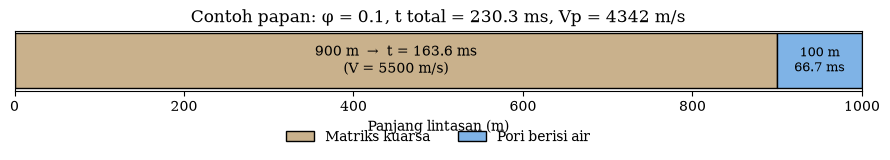

In [3]:
# Visual: lintasan gelombang yang dibagi menjadi bagian matriks dan pori
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.barh(0, (1-phi0)*L, color="#c9b18c", edgecolor="k", label="Matriks kuarsa")
ax.barh(0, phi0*L, left=(1-phi0)*L, color="#7fb3e6", edgecolor="k", label="Pori berisi air")
ax.text((1-phi0)*L/2, 0, f"{(1-phi0)*L:.0f} m  →  t = {t_ma*1e3:.1f} ms\n(V = {Vma0:.0f} m/s)", ha="center", va="center")
ax.text((1-phi0)*L + phi0*L/2, 0, f"{phi0*L:.0f} m\n{t_f*1e3:.1f} ms", ha="center", va="center", fontsize=9)
ax.set(xlim=(0, L), yticks=[], xlabel="Panjang lintasan (m)",
       title=f"Contoh papan: φ = {phi0}, t total = {t*1e3:.1f} ms, Vp = {L/t:.0f} m/s")
ax.grid(False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=2, frameon=False)
plt.tight_layout(); simpan(fig, "01_skema_lintasan_wyllie"); plt.show()

### 1.2 Relasi Gardner dan pencampuran densitas

Gardner dkk. (1974) menghubungkan densitas bulk dan kecepatan gelombang P secara empiris:

$$\rho_b=a\,V_p^{\,b}\qquad(3)$$

dengan $a=0{,}31$ dan $b=0{,}25$ untuk $V_p$ dalam m/s dan $\rho_b$ dalam g/cm³ (Mavko dkk., 2009). Relasi ini tidak memuat porositas, sehingga densitas bulk dihubungkan dengan porositas melalui pencampuran volumetrik:

$$\rho_b=\phi\,\rho_f+(1-\phi)\,\rho_{ma}\qquad(4)$$

Substitusi (4) ke bentuk invers (3) memberikan

$$V_p=\left(\frac{\phi\,\rho_f+(1-\phi)\,\rho_{ma}}{a}\right)^{1/b}\qquad(5)$$

In [4]:
def rho_bulk(phi, rho_f, rho_ma=2.65):
    # Persamaan (4): densitas bulk (g/cm3)
    return phi * rho_f + (1.0 - phi) * rho_ma

def gardner_rho(rho_b, a=0.31, b=0.25):
    # Bentuk invers Persamaan (3): Vp (m/s) dari densitas bulk
    return (rho_b / a) ** (1.0 / b)

def gardner(phi, rho_f, rho_ma=2.65, a=0.31, b=0.25):
    # Persamaan (5): Vp (m/s) model Gardner sebagai fungsi porositas
    return gardner_rho(rho_bulk(phi, rho_f, rho_ma), a, b)

rb = rho_bulk(0.10, 1.00)
print(f"rho_b = 0,10·1,00 + 0,90·2,65 = {rb:.3f} g/cm3")
print(f"Vp    = ({rb:.3f}/0,31)^(1/0,25) = {gardner(0.10, 1.00):.1f} m/s")

rho_b = 0,10·1,00 + 0,90·2,65 = 2.485 g/cm3
Vp    = (2.485/0,31)^(1/0,25) = 4129.1 m/s


### 1.3 Bentuk invers: porositas dari $V_p$

Kedua model dapat dibalik secara analitik. Dari Persamaan (2):

$$\phi=\frac{1/V_p-1/V_{ma}}{1/V_f-1/V_{ma}}\qquad(6)$$

Dari Persamaan (3) dan (4):

$$\phi=\frac{\rho_{ma}-a\,V_p^{\,b}}{\rho_{ma}-\rho_f}\qquad(7)$$

Bentuk analitik ini nanti dipakai sebagai pembanding hasil inversi iteratif pada Langkah 5a.

In [5]:
def phi_wyllie(Vp, Vf, Vma=5500.0):
    # Persamaan (6)
    return (1/Vp - 1/Vma) / (1/Vf - 1/Vma)

def phi_gardner(Vp, rho_f, rho_ma=2.65, a=0.31, b=0.25):
    # Persamaan (7)
    return (rho_ma - a * Vp**b) / (rho_ma - rho_f)

# Uji bolak-balik: phi -> Vp -> phi harus kembali ke nilai awal
for p in [0.05, 0.20, 0.35]:
    print(f"phi = {p:.2f} | Wyllie kembali ke {phi_wyllie(wyllie(p, 1500), 1500):.4f}"
          f" | Gardner kembali ke {phi_gardner(gardner(p, 1.0), 1.0):.4f}")

phi = 0.05 | Wyllie kembali ke 0.0500 | Gardner kembali ke 0.0500
phi = 0.20 | Wyllie kembali ke 0.2000 | Gardner kembali ke 0.2000
phi = 0.35 | Wyllie kembali ke 0.3500 | Gardner kembali ke 0.3500


## Langkah 2 · Parameter Model

Batupasir kuarsa dianggap jenuh 100% oleh satu jenis fluida. Kecepatan dan densitas fluida adalah nilai representatif kondisi reservoir, karena nilai sebenarnya bergantung pada tekanan, suhu, dan komposisi (Batzle & Wang, 1992). Kewajaran pasangan nilai diperiksa melalui modulus bulk $K=\rho V^2$.

In [6]:
Vma, rho_ma = 5500.0, 2.65           # matriks batupasir kuarsa
a_G, b_G = 0.31, 0.25                 # konstanta Gardner
FLUIDA = pd.DataFrame({"Vf (m/s)": [1500.0, 1300.0, 500.0],
                       "rho_f (g/cm3)": [1.00, 0.80, 0.20]},
                      index=["Air", "Minyak", "Gas"])
FLUIDA["K (GPa)"] = FLUIDA["rho_f (g/cm3)"] * 1000 * FLUIDA["Vf (m/s)"]**2 / 1e9
phi_grid = np.round(np.arange(0, 0.401, 0.05), 2)

param = pd.DataFrame({
    "Simbol": ["Vma", "rho_ma", "a", "b", "phi"],
    "Nilai": [Vma, rho_ma, a_G, b_G, "0 – 0,40 (selang 0,05)"],
    "Satuan": ["m/s", "g/cm3", "–", "–", "fraksi"]},
    index=["Kecepatan matriks", "Densitas matriks", "Konstanta Gardner", "Eksponen Gardner", "Porositas"])
display(param); display(FLUIDA.round(3))

,Simbol,Nilai,Satuan
Kecepatan matriks,Vma,5500.0,m/s
Densitas matriks,rho_ma,2.65,g/cm3
Konstanta Gardner,a,0.31,–
Eksponen Gardner,b,0.25,–
Porositas,phi,"0 – 0,40 (selang 0,05)",fraksi


,Vf (m/s),rho_f (g/cm3),K (GPa)
Air,1500.0,1.0,2.250
Minyak,1300.0,0.8,1.352
Gas,500.0,0.2,0.050


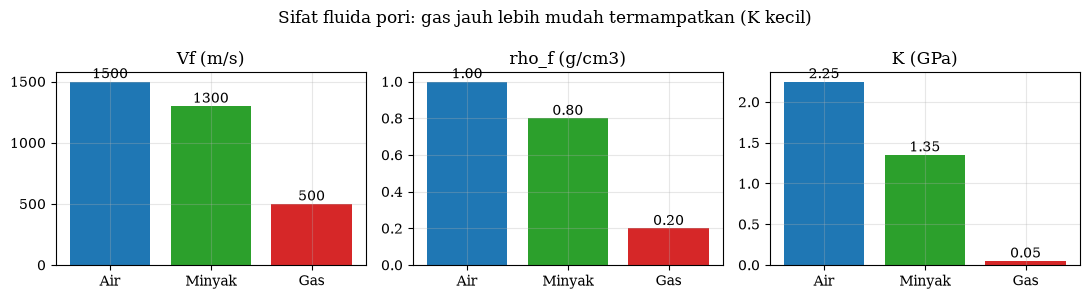

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, kol in zip(axs, FLUIDA.columns):
    ax.bar(FLUIDA.index, FLUIDA[kol], color=[WARNA[k] for k in FLUIDA.index])
    ax.set_title(kol)
    for i, v in enumerate(FLUIDA[kol]):
        ax.text(i, v, f"{v:.2f}" if v < 10 else f"{v:.0f}", ha="center", va="bottom")
fig.suptitle("Sifat fluida pori: gas jauh lebih mudah termampatkan (K kecil)")
plt.tight_layout(); simpan(fig, "02_sifat_fluida"); plt.show()

## Langkah 3 · *Forward Modeling*

*Forward modeling* menghitung data ($V_p$) dari parameter model yang diketahui ($\phi$, $V_{ma}$, $V_f$, $\rho_f$, $a$, $b$).

### 3.1 Tabel hasil

In [8]:
tabel = pd.DataFrame(index=(phi_grid*100).astype(int))
tabel.index.name = "phi (%)"
for f, (Vf, rf, _) in FLUIDA.iterrows():
    tabel[f"Wyllie {f}"] = wyllie(phi_grid, Vf, Vma)
for f, (Vf, rf, _) in FLUIDA.iterrows():
    tabel[f"Gardner {f}"] = gardner(phi_grid, rf, rho_ma, a_G, b_G)
display(tabel.round(1))

,Wyllie Air,Wyllie Minyak,Wyllie Gas,Gardner Air,Gardner Minyak,Gardner Gas
phi (%),,,,,,
0,5500.0,5500.0,5500.0,5339.9,5339.9,5339.9
5,4852.9,4735.1,3666.7,4705.4,4632.5,4418.9
10,4342.1,4157.0,2750.0,4129.1,3997.8,3622.5
15,3928.6,3704.7,2200.0,3607.5,3430.7,2939.0
20,3587.0,3341.1,1833.3,3136.9,2926.1,2357.0
25,3300.0,3042.6,1571.4,2714.0,2479.4,1866.1
30,3055.6,2793.0,1375.0,2335.3,2085.9,1456.2
35,2844.8,2581.2,1222.2,1997.7,1741.2,1117.9
40,2661.3,2399.3,1100.0,1698.1,1441.1,842.2


### 3.2 Kurva $V_p$ terhadap porositas

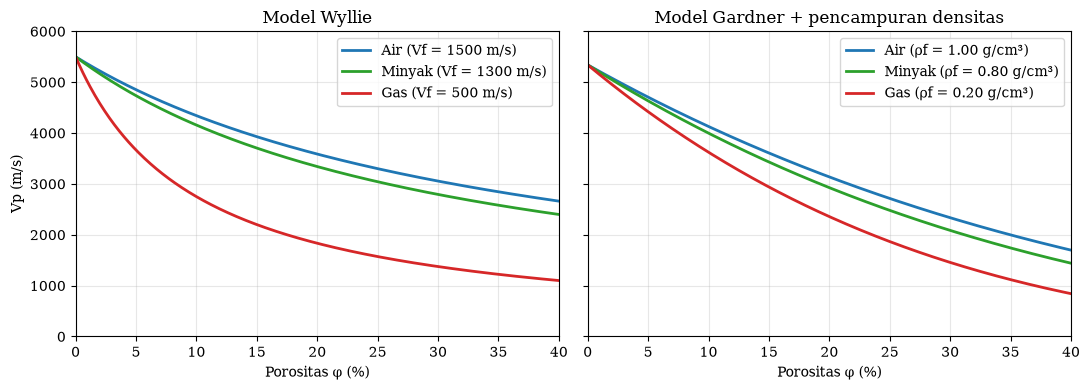

In [9]:
pf = np.linspace(0, 0.40, 401)
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for f, (Vf, rf, _) in FLUIDA.iterrows():
    axs[0].plot(pf*100, wyllie(pf, Vf, Vma), color=WARNA[f], lw=2, label=f"{f} (Vf = {Vf:.0f} m/s)")
    axs[1].plot(pf*100, gardner(pf, rf), color=WARNA[f], lw=2, label=f"{f} (ρf = {rf:.2f} g/cm³)")
for ax, judul in zip(axs, ["Model Wyllie", "Model Gardner + pencampuran densitas"]):
    ax.set(title=judul, xlabel="Porositas φ (%)", xlim=(0, 40), ylim=(0, 6000)); ax.legend()
axs[0].set_ylabel("Vp (m/s)")
plt.tight_layout(); simpan(fig, "03_forward_kurva_vp"); plt.show()

### 3.3 *Slowness* terhadap porositas

Pada model Wyllie, *slowness* $1/V_p$ berubah **linear** terhadap $\phi$ (Persamaan 2), sehingga kurva $V_p$-nya berbentuk hiperbolik. Pada model Gardner, *slowness* tidak linear terhadap $\phi$.

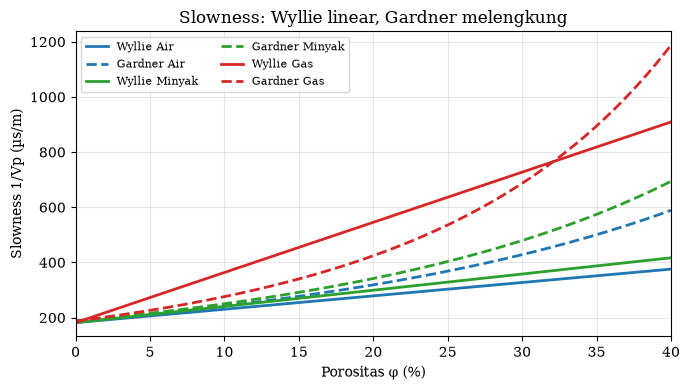

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for f, (Vf, rf, _) in FLUIDA.iterrows():
    ax.plot(pf*100, 1e6/wyllie(pf, Vf), color=WARNA[f], lw=2, label=f"Wyllie {f}")
    ax.plot(pf*100, 1e6/gardner(pf, rf), color=WARNA[f], lw=2, ls="--", label=f"Gardner {f}")
ax.set(xlabel="Porositas φ (%)", ylabel="Slowness 1/Vp (µs/m)", xlim=(0, 40),
       title="Slowness: Wyllie linear, Gardner melengkung")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); simpan(fig, "04_forward_slowness"); plt.show()

### 3.4 Peta $V_p$ terhadap porositas dan sifat fluida

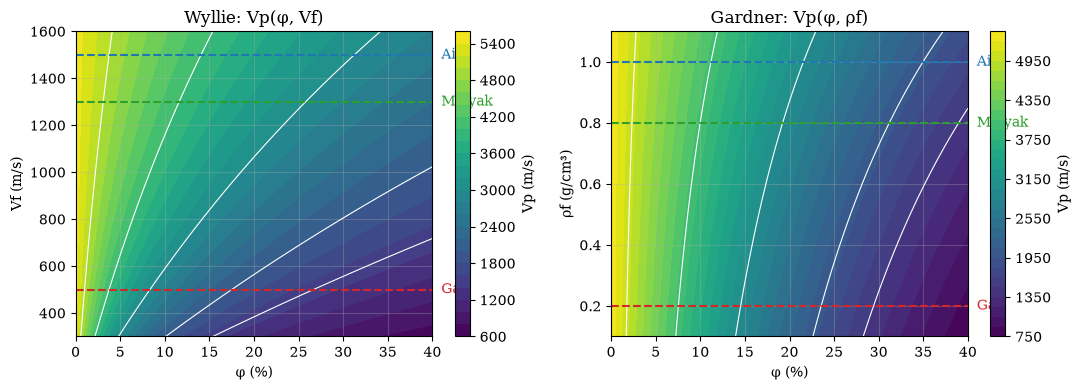

In [11]:
PH, VF = np.meshgrid(np.linspace(0, 0.4, 200), np.linspace(300, 1600, 200))
PH2, RF = np.meshgrid(np.linspace(0, 0.4, 200), np.linspace(0.1, 1.1, 200))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
c0 = axs[0].contourf(PH*100, VF, wyllie(PH, VF), levels=30, cmap="viridis")
axs[0].contour(PH*100, VF, wyllie(PH, VF), levels=[1500, 2000, 3000, 4000, 5000], colors="w", linewidths=0.8)
c1 = axs[1].contourf(PH2*100, RF, gardner(PH2, RF), levels=30, cmap="viridis")
axs[1].contour(PH2*100, RF, gardner(PH2, RF), levels=[1500, 2000, 3000, 4000, 5000], colors="w", linewidths=0.8)
for f, (Vf, rf, _) in FLUIDA.iterrows():
    axs[0].axhline(Vf, color=WARNA[f], ls="--"); axs[0].text(41, Vf, f, va="center", color=WARNA[f])
    axs[1].axhline(rf, color=WARNA[f], ls="--"); axs[1].text(41, rf, f, va="center", color=WARNA[f])
axs[0].set(title="Wyllie: Vp(φ, Vf)", xlabel="φ (%)", ylabel="Vf (m/s)")
axs[1].set(title="Gardner: Vp(φ, ρf)", xlabel="φ (%)", ylabel="ρf (g/cm³)")
fig.colorbar(c0, ax=axs[0], label="Vp (m/s)"); fig.colorbar(c1, ax=axs[1], label="Vp (m/s)")
plt.tight_layout(); simpan(fig, "05_forward_peta_vp"); plt.show()

### 3.5 Sensitivitas $dV_p/d\phi$

Turunan analitik model Wyllie adalah $dV_p/d\phi=-V_p^2\,(1/V_f-1/V_{ma})$. Nilai ini menunjukkan seberapa besar perubahan $V_p$ untuk setiap kenaikan porositas, dan nanti juga dipakai oleh metode Newton.

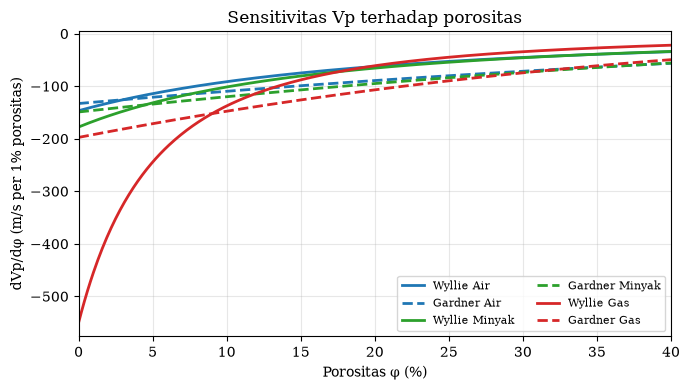

In [12]:
def dVp_dphi_wyllie(phi, Vf, Vma=5500.0):
    return -wyllie(phi, Vf, Vma)**2 * (1/Vf - 1/Vma)

fig, ax = plt.subplots(figsize=(7, 4))
for f, (Vf, rf, _) in FLUIDA.iterrows():
    ax.plot(pf*100, dVp_dphi_wyllie(pf, Vf)/100, color=WARNA[f], lw=2, label=f"Wyllie {f}")
    ax.plot(pf*100, np.gradient(gardner(pf, rf), pf)/100, color=WARNA[f], lw=2, ls="--", label=f"Gardner {f}")
ax.set(xlabel="Porositas φ (%)", ylabel="dVp/dφ (m/s per 1% porositas)", xlim=(0, 40),
       title="Sensitivitas Vp terhadap porositas")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); simpan(fig, "06_forward_sensitivitas"); plt.show()

## Langkah 4 · Data Observasi

### 4.1 Data sintetik

Data sintetik dibuat dari parameter "sebenarnya" yang diketahui, lalu diberi *noise* acak 2%. Karena jawabannya diketahui, data ini dipakai untuk menguji apakah inversi mampu menemukan kembali parameter tersebut.

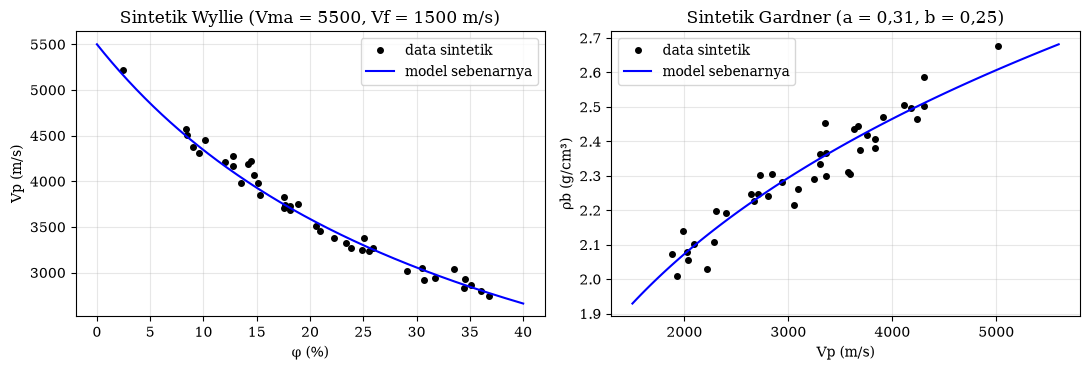

In [13]:
N, NOISE = 40, 0.02
BENAR_W = dict(Vma=5500.0, Vf=1500.0)       # parameter sebenarnya, Wyllie (jenuh air)
BENAR_G = dict(a=0.31, b=0.25)              # parameter sebenarnya, Gardner

phi_sin = np.sort(rng.uniform(0.02, 0.38, N))
Vp_sin_W = wyllie(phi_sin, BENAR_W["Vf"], BENAR_W["Vma"]) * (1 + NOISE*rng.standard_normal(N))
Vp_sin_G = gardner(phi_sin, 1.00, **BENAR_G)                                 # Vp sebenarnya (jenuh air)
rho_sin  = rho_bulk(phi_sin, 1.00) * (1 + NOISE*rng.standard_normal(N))        # densitas "terukur" + noise

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(phi_sin*100, Vp_sin_W, "ko", ms=4, label="data sintetik")
axs[0].plot(pf*100, wyllie(pf, BENAR_W["Vf"], BENAR_W["Vma"]), "b-", label="model sebenarnya")
axs[0].set(title="Sintetik Wyllie (Vma = 5500, Vf = 1500 m/s)", xlabel="φ (%)", ylabel="Vp (m/s)")
rr = np.linspace(1.9, 2.65, 100); vv = np.linspace(1500, 5600, 100)
axs[1].plot(Vp_sin_G, rho_sin, "ko", ms=4, label="data sintetik")
axs[1].plot(vv, 0.31*vv**0.25, "b-", label="model sebenarnya")
axs[1].set(title="Sintetik Gardner (a = 0,31, b = 0,25)", xlabel="Vp (m/s)", ylabel="ρb (g/cm³)")
for ax in axs: ax.legend()
plt.tight_layout(); simpan(fig, "07_data_sintetik"); plt.show()

### 4.2 Data sumur 15/9-F-11 T2 (Lapangan Volve)

Data sumur berasal dari rilis data Lapangan Volve (Equinor, 2018) dan sama dengan data pada tugas identifikasi well log. Langkah pengolahannya sebagai berikut.

1. **QC**: sampel dipakai bila AC, DEN, GR, dan PEF tersedia serta |DENC| ≤ 0,15 g/cm³ (kriteria QC tugas well log).
2. **Pemilihan batupasir**: $I_{GR}<0{,}3$ dan PEF < 7,0 b/e, mengikuti aturan klasifikasi litologi pada tugas well log, dengan $GR_{min}=4{,}12$ dan $GR_{max}=129{,}30$ gAPI.
3. **Kecepatan**: $V_p = 304\,800/AC$, karena AC dalam µs/ft dan 1 ft = 0,3048 m.
4. **Porositas densitas**: $\phi_D=(\rho_{ma}-\rho_b)/(\rho_{ma}-\rho_f)$ dengan $\rho_{ma}=2{,}65$ dan $\rho_f=1{,}00$ g/cm³. Asumsi $\rho_f=1{,}00$ mengabaikan kemungkinan hidrokarbon di dalam pori, sehingga $\phi_D$ pada zona berhidrokarbon dapat sedikit terlalu besar.

$\phi_D$ dihitung dari log densitas, bukan dari log sonik, sehingga dapat dipakai sebagai porositas "pengamatan" yang independen dari $V_p$.

In [14]:
def baca_las(path):
    teks = open(path).read()
    kurva = teks[teks.find("~C"):teks.find("~", teks.find("~C") + 2)]
    nama = [b.split(".")[0].strip() for b in kurva.splitlines()[1:] if b.strip() and not b.startswith("#")]
    data = np.array([b.split() for b in teks[teks.find("~A"):].splitlines()[1:] if b.strip()], float)
    df = pd.DataFrame(data, columns=nama).replace(-999.25, np.nan)
    return df

log = baca_las("data/15_9-F-11_T2.las")
GRmin, GRmax = 4.12, 129.30
log["Vp"]   = 304800.0 / log["AC"]
log["IGR"]  = ((log["GR"] - GRmin) / (GRmax - GRmin)).clip(0, 1)
log["phiD"] = (2.65 - log["DEN"]) / (2.65 - 1.00)
qc = log[["AC", "DEN", "GR", "PEF"]].notna().all(axis=1) & (log["DENC"].abs() <= 0.15)
pasir = qc & (log["IGR"] < 0.3) & (log["PEF"] < 7.0)
log["Zona"] = pd.cut(log["DEPTH"], [2577, 2820, 4090, 4150, 4380, 4540], labels=["Z1", "Z2", "Z3", "Z4", "Z5"])
sw = log[pasir].copy()

print(f"Sampel lolos QC     : {qc.sum():,}")
print(f"Sampel batupasir    : {pasir.sum():,}")
display(sw.groupby("Zona", observed=True).agg(n=("Vp", "size"), DEPTH_min=("DEPTH", "min"), DEPTH_max=("DEPTH", "max"),
        Vp_median=("Vp", "median"), phiD_median=("phiD", "median"), DEN_median=("DEN", "median")).round(3))

Sampel lolos QC     : 19,431
Sampel batupasir    : 2,521


,n,DEPTH_min,DEPTH_max,Vp_median,phiD_median,DEN_median
Zona,,,,,,
Z1,1619,2583.6,2820.0,3120.831,0.272,2.201
Z2,11,2820.1,2821.1,3973.386,0.228,2.274
Z5,891,4393.7,4507.4,4030.131,0.170,2.370


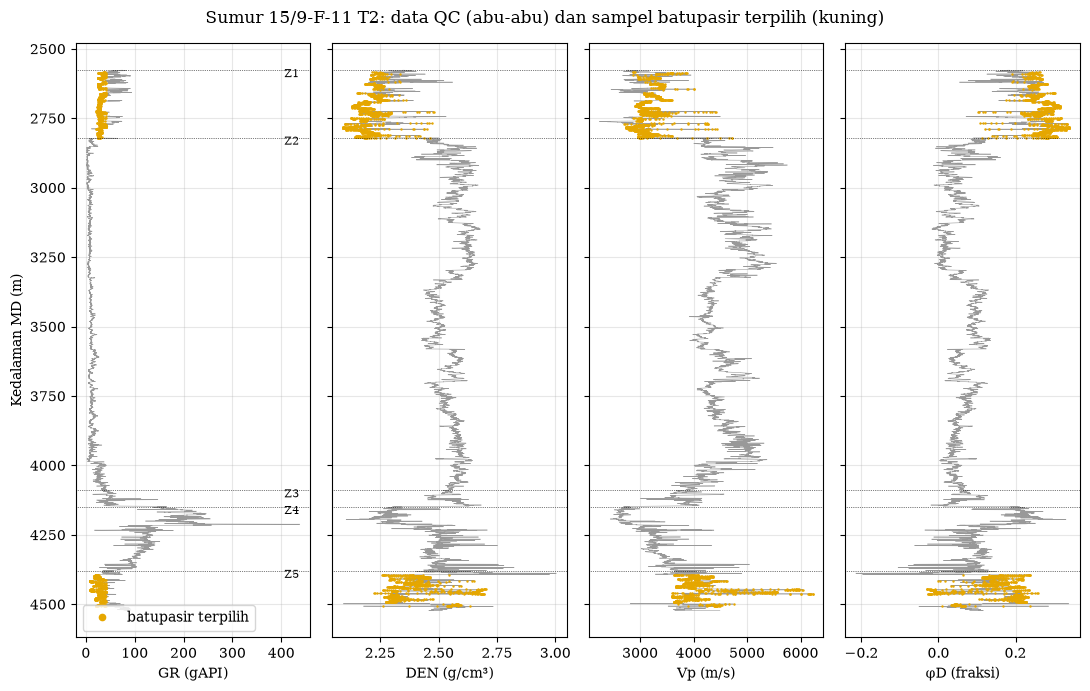

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(11, 7), sharey=True)
d = log[qc]
for ax, kol, lab in zip(axs, ["GR", "DEN", "Vp", "phiD"], ["GR (gAPI)", "DEN (g/cm³)", "Vp (m/s)", "φD (fraksi)"]):
    ax.plot(d[kol], d["DEPTH"], color="0.6", lw=0.4)
    ax.plot(sw[kol], sw["DEPTH"], ".", color="#e6a700", ms=1.5, label="batupasir terpilih")
    ax.set_xlabel(lab)
for z, top in zip(["Z1", "Z2", "Z3", "Z4", "Z5"], [2577, 2820, 4090, 4150, 4380]):
    for ax in axs: ax.axhline(top, color="k", lw=0.5, ls=":")
    axs[0].text(axs[0].get_xlim()[1]*0.95, top + 25, z, ha="right", fontsize=8)
axs[0].set_ylabel("Kedalaman MD (m)"); axs[0].invert_yaxis(); axs[0].legend(loc="lower left", markerscale=6)
fig.suptitle("Sumur 15/9-F-11 T2: data QC (abu-abu) dan sampel batupasir terpilih (kuning)")
plt.tight_layout(); simpan(fig, "08_log_sumur"); plt.show()

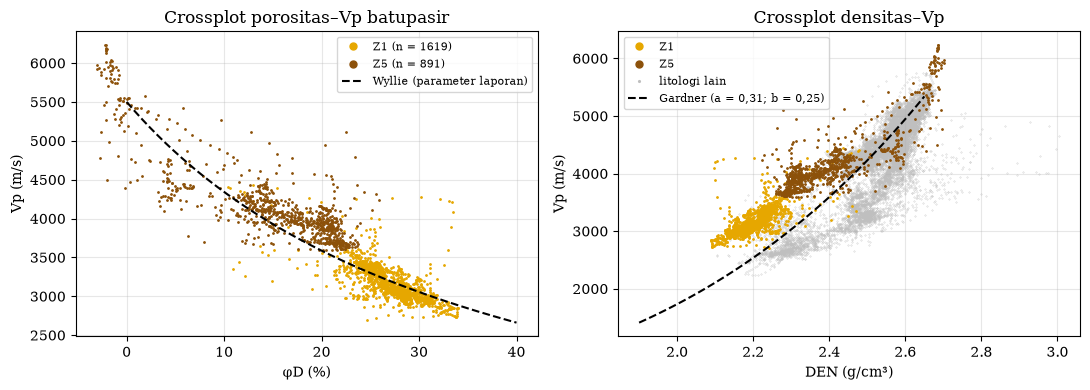

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for z, c in [("Z1", "#e6a700"), ("Z5", "#8c510a")]:
    s = sw[sw["Zona"] == z]
    axs[0].plot(s["phiD"]*100, s["Vp"], ".", ms=2, color=c, label=f"{z} (n = {len(s)})")
    axs[1].plot(s["DEN"], s["Vp"], ".", ms=2, color=c, label=f"{z}")
axs[1].plot(log.loc[qc & ~pasir, "DEN"], log.loc[qc & ~pasir, "Vp"], ".", ms=0.5, color="0.75", zorder=0, label="litologi lain")
axs[0].plot(pf*100, wyllie(pf, 1500, 5500), "k--", label="Wyllie (parameter laporan)")
axs[1].plot(rr, gardner_rho(rr), "k--", label="Gardner (a = 0,31; b = 0,25)")
axs[0].set(xlabel="φD (%)", ylabel="Vp (m/s)", title="Crossplot porositas–Vp batupasir")
axs[1].set(xlabel="DEN (g/cm³)", ylabel="Vp (m/s)", title="Crossplot densitas–Vp")
for ax in axs: ax.legend(markerscale=5, fontsize=8)
plt.tight_layout(); simpan(fig, "09_crossplot_sumur"); plt.show()

## Langkah 5a · Inversi Porositas dari $V_p$ (Metode Newton)

Diberikan satu nilai $V_p$ terukur, porositas dicari sebagai akar dari

$$f(\phi)=V_p^{model}(\phi)-V_p^{obs}=0$$

Metode Newton memperbarui tebakan dengan garis singgung:

$$\phi_{k+1}=\phi_k-\frac{f(\phi_k)}{f'(\phi_k)}\qquad(8)$$

Perhitungan menggunakan `scipy.optimize.newton`. Setiap tebakan yang dievaluasi dicatat, lalu ditayangkan satu per satu. Hasil akhirnya dibandingkan dengan solusi analitik Persamaan (6) dan (7).

In [17]:
def newton_tercatat(f, fprime, x0):
    riwayat = []
    def f_catat(x):
        riwayat.append(float(x)); return f(x)
    akar = newton(f_catat, x0, fprime=fprime, tol=1e-10, maxiter=50)
    return akar, np.array(riwayat)

def tayang_newton(f, fprime, riwayat, judul, nama):
    xx = np.linspace(-0.02, 0.45, 300)
    for k in range(len(riwayat)):
        clear_output(wait=True)
        fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
        axs[0].plot(xx*100, f(xx), "k-", lw=1.5); axs[0].axhline(0, color="0.4", lw=0.8)
        for j in range(k + 1):
            x = riwayat[j]
            axs[0].plot(x*100, f(x), "o", color="C3" if j == k else "C0")
            if j < k:
                x2 = riwayat[j + 1]
                axs[0].plot([x*100, x2*100], [f(x), 0], "--", color="C0", lw=1)
                axs[0].plot([x2*100, x2*100], [0, f(x2)], ":", color="0.5", lw=1)
        axs[0].set(xlabel="φ (%)", ylabel="f(φ) = Vp model − Vp obs (m/s)", title=f"{judul}: iterasi {k}")
        axs[1].semilogy(range(k + 1), np.abs(f(riwayat[:k + 1])) + 1e-12, "o-")
        axs[1].set(xlabel="Iterasi", ylabel="|f(φ)| (m/s)", title="Galat tiap iterasi", xlim=(-0.5, len(riwayat) - 0.5))
        plt.tight_layout(); display(fig)
        if k == len(riwayat) - 1: simpan(fig, nama)
        plt.close(fig); time.sleep(JEDA)
    display(pd.DataFrame({"phi (%)": riwayat*100, "f(phi) (m/s)": f(riwayat)}).rename_axis("iterasi").round(6))

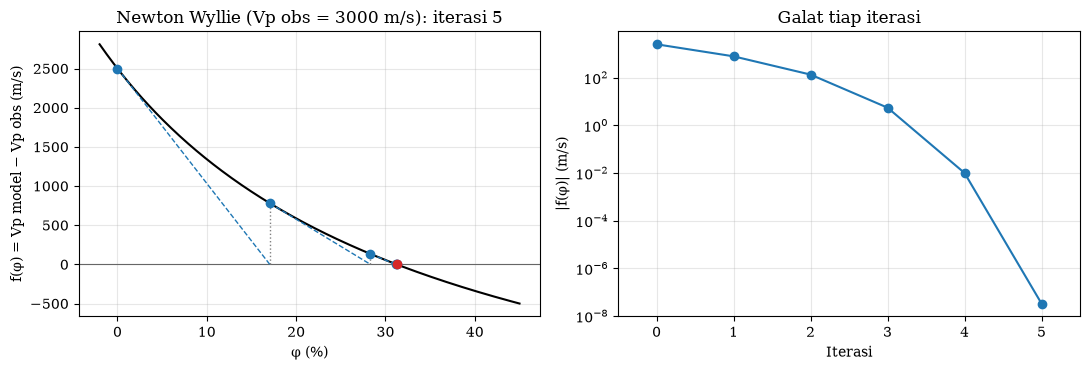

,phi (%),f(phi) (m/s)
iterasi,,
0,0.000000,2500.000000
1,17.045455,781.250000
2,28.315177,133.775685
3,31.124717,5.476864
4,31.249772,0.009962
5,31.250000,0.000000


Newton   : φ = 31.2500 %
Analitik : φ = 31.2500 %  (Persamaan 6)


In [18]:
# Kasus 1: Wyllie, batupasir jenuh air, Vp terukur = 3000 m/s
Vobs = 3000.0
fW  = lambda p: wyllie(p, 1500) - Vobs
fWp = lambda p: dVp_dphi_wyllie(p, 1500)
phi_N, rw = newton_tercatat(fW, fWp, x0=0.0)
tayang_newton(fW, fWp, rw, "Newton Wyllie (Vp obs = 3000 m/s)", "10_newton_wyllie")
print(f"Newton   : φ = {phi_N*100:.4f} %")
print(f"Analitik : φ = {phi_wyllie(Vobs, 1500)*100:.4f} %  (Persamaan 6)")

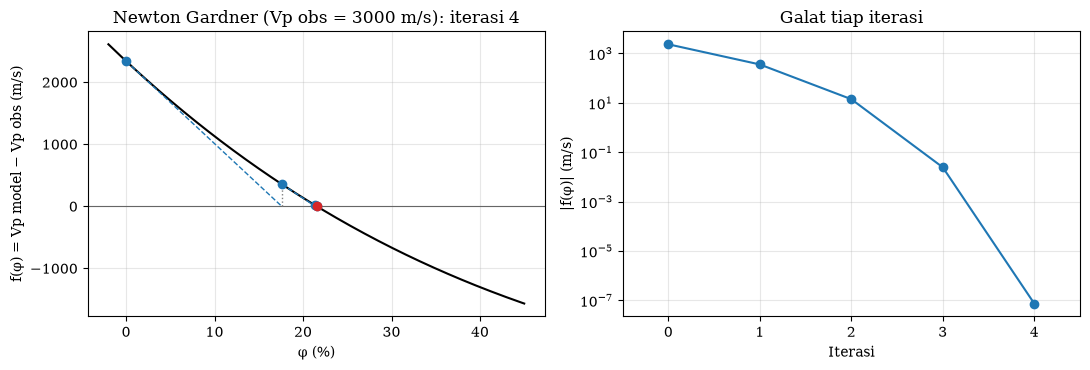

,phi (%),f(phi) (m/s)
iterasi,,
0,0.000000,2339.944219
1,17.594249,357.195557
2,21.398256,14.000659
3,21.559918,0.024370
4,21.560200,0.000000


Newton   : φ = 21.5602 %
Analitik : φ = 21.5602 %  (Persamaan 7)


In [19]:
# Kasus 2: Gardner, batupasir jenuh air, Vp terukur = 3000 m/s
fG  = lambda p: gardner(p, 1.0) - Vobs
fGp = lambda p: 4 * gardner(p, 1.0) / rho_bulk(p, 1.0) * (1.0 - 2.65)   # dVp/dphi = (1/b)·Vp/rho·(rho_f - rho_ma)
phi_NG, rg = newton_tercatat(fG, fGp, x0=0.0)
tayang_newton(fG, fGp, rg, "Newton Gardner (Vp obs = 3000 m/s)", "11_newton_gardner")
print(f"Newton   : φ = {phi_NG*100:.4f} %")
print(f"Analitik : φ = {phi_gardner(Vobs, 1.0)*100:.4f} %  (Persamaan 7)")

Inversi yang sama dapat diterapkan pada setiap sampel log. Porositas dari log sonik ($\phi_S$, hasil inversi Wyllie dan Gardner) dibandingkan dengan porositas densitas $\phi_D$ yang independen.

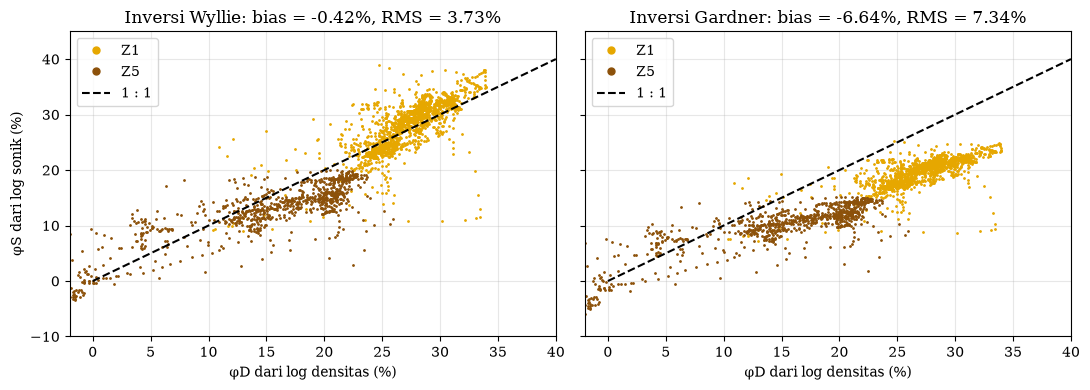

In [20]:
sw["phiS_W"] = phi_wyllie(sw["Vp"], 1500, 5500)
sw["phiS_G"] = phi_gardner(sw["Vp"], 1.0)
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, kol, judul in zip(axs, ["phiS_W", "phiS_G"], ["Inversi Wyllie", "Inversi Gardner"]):
    for z, c in [("Z1", "#e6a700"), ("Z5", "#8c510a")]:
        s = sw[sw["Zona"] == z]; ax.plot(s["phiD"]*100, s[kol]*100, ".", ms=2, color=c, label=z)
    ax.plot([0, 40], [0, 40], "k--", label="1 : 1")
    r = sw[kol] - sw["phiD"]
    ax.set(xlabel="φD dari log densitas (%)", title=f"{judul}: bias = {r.mean()*100:+.2f}%, RMS = {np.sqrt((r**2).mean())*100:.2f}%",
           xlim=(-2, 40), ylim=(-10, 45)); ax.legend(markerscale=5)
axs[0].set_ylabel("φS dari log sonik (%)")
plt.tight_layout(); simpan(fig, "12_inversi_phi_sumur"); plt.show()

## Langkah 5b · Inversi Parameter Model

Pada tahap ini yang dicari adalah parameter model $\mathbf{m}$, bukan porositas. Untuk model Wyllie, $\mathbf{m}=(V_{ma},V_f)$ dengan data $V_p$ sebagai fungsi $\phi$. Untuk model Gardner, $\mathbf{m}=(a,b)$ dengan data $\rho_b$ sebagai fungsi $V_p$, sesuai bentuk asli Persamaan (3). Bentuk asli ini dipilih karena bentuk inversnya, $V_p=(\rho_b/a)^{1/b}$, sangat peka terhadap $b$ sehingga mudah menghasilkan nilai tak hingga selama iterasi. Parameter dicari dari banyak data sekaligus dengan meminimumkan fungsi misfit kuadrat terkecil (Aster dkk., 2018):

$$\Phi(\mathbf{m})=\frac{1}{N}\sum_{i=1}^{N}\left(\frac{d_i^{model}(\mathbf{m})-d_i^{obs}}{d_i^{obs}}\right)^2\qquad(9)$$

Misfit dinyatakan relatif agar tidak bergantung pada satuan. Untuk pelaporan, dipakai juga misfit RMS dalam satuan data (m/s untuk Wyllie, g/cm³ untuk Gardner).

Minimisasi dilakukan dengan `scipy.optimize.minimize` metode **BFGS**, yaitu metode quasi-Newton. Fungsi `callback` mencatat parameter pada setiap iterasi. Kecepatan diskalakan ke km/s supaya kedua parameter memiliki orde besaran yang sama. Setiap iterasi ditayangkan dalam tiga panel:

- kiri: data dan kurva model iterasi ke-*k*;
- tengah: misfit RMS terhadap iterasi;
- kanan: lintasan parameter di atas peta kontur misfit.

In [21]:
def inversi(model, x, d_obs, m0, skala):
    # model(x, m) -> d_model ; m dalam satuan asli, q = m/skala adalah variabel optimasi
    skala = np.asarray(skala, float)
    phi_fn = lambda q: np.mean(((model(x, q*skala) - d_obs) / d_obs)**2)
    riwayat = [np.asarray(m0, float) / skala]
    hasil = minimize(phi_fn, riwayat[0], method="BFGS", callback=lambda qk: riwayat.append(np.copy(qk)),
                     options={"gtol": 1e-10, "maxiter": 200})
    M = np.array(riwayat) * skala
    rms = np.array([np.sqrt(np.mean((model(x, m) - d_obs)**2)) for m in M])
    return M, rms, hasil

def peta_misfit(model, x, d_obs, r1, r2):
    A, B = np.meshgrid(r1, r2)
    Z = np.array([[np.sqrt(np.mean((model(x, (p, q)) - d_obs)**2)) for p in r1] for q in r2])
    return A, B, Z

def tayang_inversi(model, x, d_obs, M, rms, peta, label, xlab, nama, x_kurva, benar=None, judul="",
                   ylab="Vp (m/s)", sat="m/s", fmt=".1f", label_benar="sebenarnya"):
    A, B, Z = peta
    for k in range(len(M)):
        clear_output(wait=True)
        fig, axs = plt.subplots(1, 3, figsize=(14, 4))
        axs[0].plot(x, d_obs, "k.", ms=3, alpha=0.5, label="data")
        for j in range(k):
            axs[0].plot(x_kurva, model(x_kurva, M[j]), color="0.75", lw=0.8)
        axs[0].plot(x_kurva, model(x_kurva, M[k]), "C3", lw=2, label=f"model iterasi {k}")
        axs[0].set(xlabel=xlab, ylabel=ylab, title=judul); axs[0].legend(fontsize=8)
        axs[1].semilogy(range(k + 1), rms[:k + 1], "o-", color="C3")
        axs[1].set(xlabel="Iterasi", ylabel=f"Misfit RMS ({sat})", xlim=(-0.5, len(M) - 0.5),
                   ylim=(rms.min()*0.8, rms.max()*1.3), title=f"RMS = {rms[k]:{fmt}} {sat}")
        cs = axs[2].contourf(A, B, np.log10(Z), levels=30, cmap="viridis")
        axs[2].plot(M[:k + 1, 0], M[:k + 1, 1], "w.-", lw=1.5)
        axs[2].plot(M[k, 0], M[k, 1], "o", color="C3", ms=8)
        if benar is not None: axs[2].plot(*benar, "w*", ms=14, mec="k", label=label_benar)
        axs[2].set(xlabel=label[0], ylabel=label[1],
                   title=f"{label[0]} = {M[k,0]:.4g}, {label[1]} = {M[k,1]:.4g}")
        if benar is not None: axs[2].legend(loc="upper right", fontsize=8)
        fig.colorbar(cs, ax=axs[2], label=f"log10 RMS ({sat})")
        plt.tight_layout(); display(fig)
        if k == len(M) - 1: simpan(fig, nama)
        plt.close(fig); time.sleep(JEDA)

def tabel_riwayat(M, rms, label, sat="m/s"):
    return pd.DataFrame({label[0]: M[:, 0], label[1]: M[:, 1], f"RMS ({sat})": rms}).rename_axis("iterasi")

model_W = lambda phi, m: wyllie(phi, m[1], m[0])        # m = (Vma, Vf)
model_G = lambda vp, m: m[0] * vp**m[1]                  # Persamaan (3), m = (a, b)

### 5b.1 Wyllie pada data sintetik

Tebakan awal sengaja dibuat jauh dari nilai sebenarnya, yaitu $V_{ma}=4000$ m/s dan $V_f=2500$ m/s. Nilai sebenarnya adalah 5500 dan 1500 m/s (bintang putih).

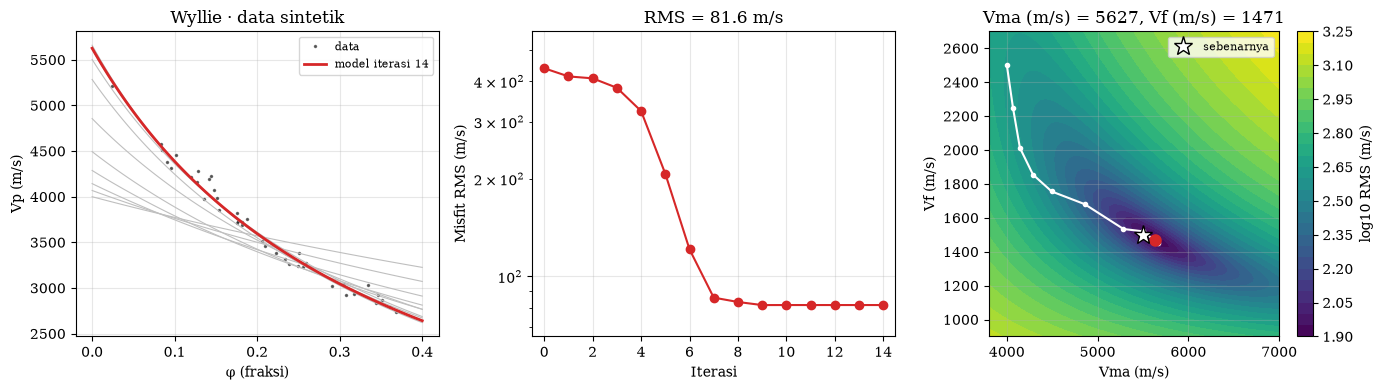

,Vma (m/s),Vf (m/s),RMS (m/s)
iterasi,,,
0,4000.00,2500.00,438.40
1,4068.23,2246.52,413.75
2,4143.43,2013.28,408.16
3,4287.71,1854.86,381.66
4,4493.98,1755.37,323.55
5,4856.10,1680.89,207.24
6,5284.46,1534.07,121.16
7,5503.65,1519.99,86.00
8,5659.91,1451.45,83.37


In [22]:
M_ws, rms_ws, h_ws = inversi(model_W, phi_sin, Vp_sin_W, m0=(4000, 2500), skala=(1000, 1000))
peta_ws = peta_misfit(model_W, phi_sin, Vp_sin_W, np.linspace(3800, 7000, 90), np.linspace(900, 2700, 90))
tayang_inversi(model_W, phi_sin, Vp_sin_W, M_ws, rms_ws, peta_ws, ("Vma (m/s)", "Vf (m/s)"), "φ (fraksi)",
               "13_inversi_wyllie_sintetik", np.linspace(0, 0.4, 100), benar=(5500, 1500), judul="Wyllie · data sintetik")
display(tabel_riwayat(M_ws, rms_ws, ("Vma (m/s)", "Vf (m/s)")).round(2))

### 5b.2 Gardner pada data sintetik

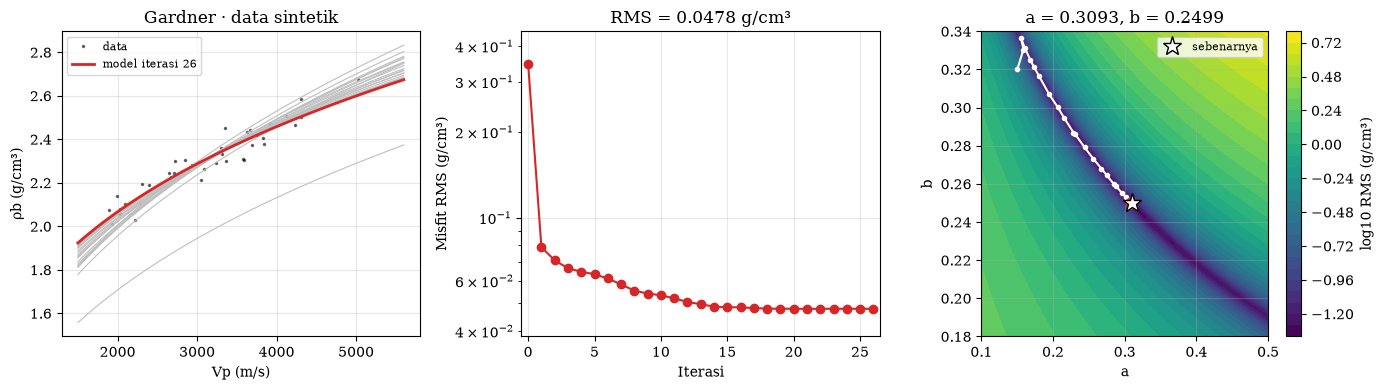

,a,b,RMS (g/cm³)
iterasi,,,
0,0.15000,0.32000,0.34607
1,0.15870,0.33045,0.07871
2,0.15542,0.33635,0.07079
3,0.16049,0.33144,0.06636
4,0.16806,0.32519,0.06455
5,0.17335,0.32131,0.06322
6,0.18006,0.31680,0.06111
7,0.19467,0.30694,0.05826
8,0.20649,0.30023,0.05539


In [23]:
M_gs, rms_gs, h_gs = inversi(model_G, Vp_sin_G, rho_sin, m0=(0.15, 0.32), skala=(1, 1))
peta_gs = peta_misfit(model_G, Vp_sin_G, rho_sin, np.linspace(0.10, 0.50, 90), np.linspace(0.18, 0.34, 90))
tayang_inversi(model_G, Vp_sin_G, rho_sin, M_gs, rms_gs, peta_gs, ("a", "b"), "Vp (m/s)",
               "14_inversi_gardner_sintetik", np.linspace(1500, 5600, 100), benar=(0.31, 0.25), judul="Gardner · data sintetik",
               ylab="ρb (g/cm³)", sat="g/cm³", fmt=".4f")
display(tabel_riwayat(M_gs, rms_gs, ("a", "b"), "g/cm³").round(5))

### 5b.3 Wyllie pada data sumur (batupasir)

Data yang dipakai adalah $\phi_D$ dan $V_p$ dari seluruh sampel batupasir terpilih.

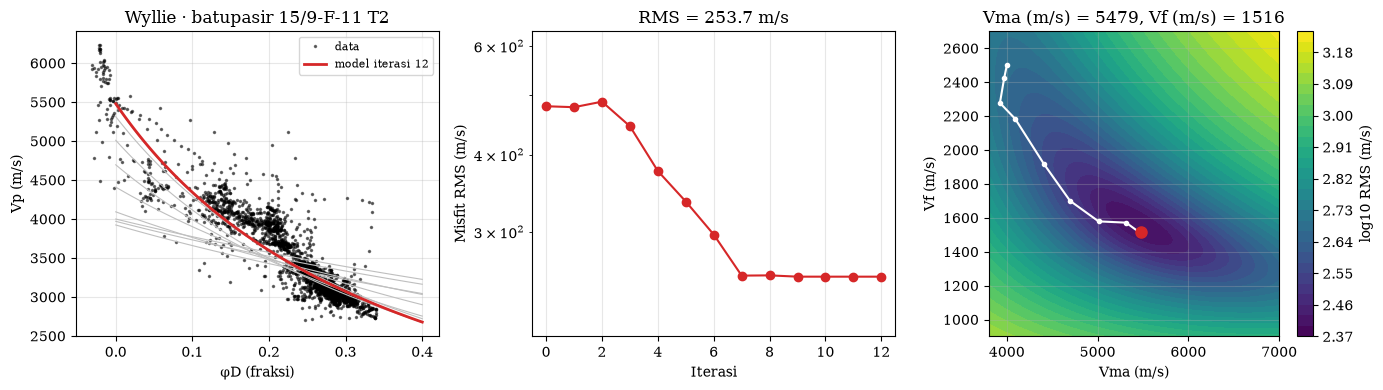

,Vma (m/s),Vf (m/s),RMS (m/s)
iterasi,,,
0,4000.00,2500.00,479.06
1,3970.31,2424.07,477.38
2,3923.66,2277.73,487.29
3,4092.29,2183.43,444.61
4,4409.05,1916.97,376.20
5,4695.51,1700.50,335.76
6,5010.18,1579.04,296.84
7,5313.43,1571.47,254.69
8,5468.13,1511.30,254.93


In [24]:
x_wd, d_wd = sw["phiD"].to_numpy(), sw["Vp"].to_numpy()
M_wd, rms_wd, h_wd = inversi(model_W, x_wd, d_wd, m0=(4000, 2500), skala=(1000, 1000))
peta_wd = peta_misfit(model_W, x_wd, d_wd, np.linspace(3800, 7000, 70), np.linspace(900, 2700, 70))
tayang_inversi(model_W, x_wd, d_wd, M_wd, rms_wd, peta_wd, ("Vma (m/s)", "Vf (m/s)"), "φD (fraksi)",
               "15_inversi_wyllie_sumur", np.linspace(0, 0.4, 100), judul="Wyllie · batupasir 15/9-F-11 T2")
display(tabel_riwayat(M_wd, rms_wd, ("Vma (m/s)", "Vf (m/s)")).round(2))

### 5b.4 Gardner pada data sumur

Relasi Gardner berlaku umum untuk batuan sedimen, sehingga inversi dilakukan pada **seluruh sampel lolos QC** (semua litologi). Hasilnya kemudian dibandingkan dengan inversi pada batupasir saja.

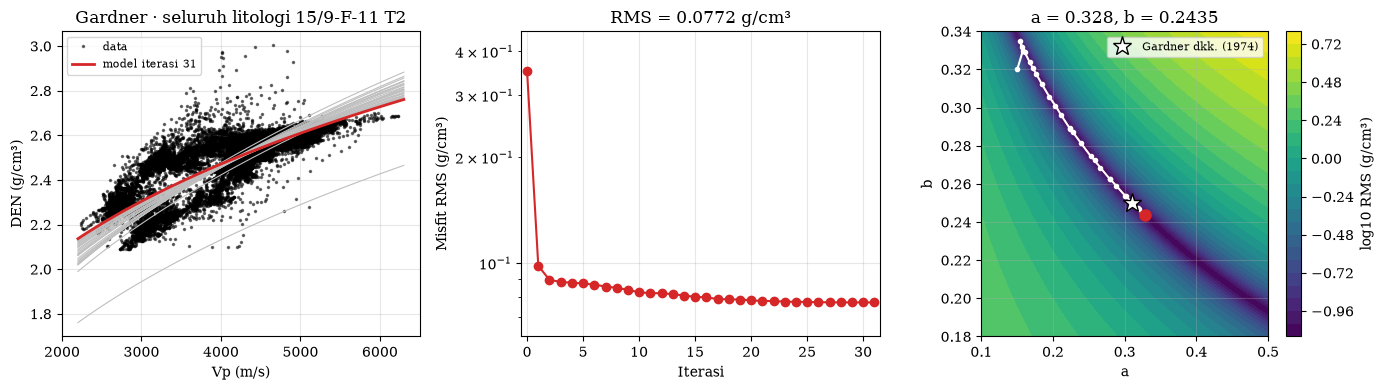

,a,b,RMS (g/cm³)
iterasi,,,
0,0.15000,0.32000,0.35032
1,0.15760,0.32947,0.09807
2,0.15402,0.33487,0.08950
3,0.15688,0.33201,0.08827
4,0.16039,0.32918,0.08787
5,0.16733,0.32383,0.08739
6,0.17135,0.32102,0.08675
7,0.17637,0.31778,0.08565
8,0.18443,0.31227,0.08496


In [25]:
dq = log[qc]
x_gd, d_gd = dq["Vp"].to_numpy(), dq["DEN"].to_numpy()
M_gd, rms_gd, h_gd = inversi(model_G, x_gd, d_gd, m0=(0.15, 0.32), skala=(1, 1))
peta_gd = peta_misfit(model_G, x_gd, d_gd, np.linspace(0.10, 0.50, 70), np.linspace(0.18, 0.34, 70))
tayang_inversi(model_G, x_gd, d_gd, M_gd, rms_gd, peta_gd, ("a", "b"), "Vp (m/s)",
               "16_inversi_gardner_sumur", np.linspace(2200, 6300, 100), benar=(0.31, 0.25),
               judul="Gardner · seluruh litologi 15/9-F-11 T2", ylab="DEN (g/cm³)", sat="g/cm³", fmt=".4f",
               label_benar="Gardner dkk. (1974)")
display(tabel_riwayat(M_gd, rms_gd, ("a", "b"), "g/cm³").round(5))

In [26]:
# Gardner khusus batupasir (tanpa animasi), sebagai pembanding
M_gp, rms_gp, _ = inversi(model_G, sw["Vp"].to_numpy(), sw["DEN"].to_numpy(), m0=(0.15, 0.32), skala=(1, 1))
ringkas = pd.DataFrame({
    "Data": ["Sintetik", "Sintetik", "Sumur: batupasir", "Sumur: seluruh litologi", "Sumur: batupasir"],
    "Model": ["Wyllie", "Gardner", "Wyllie", "Gardner", "Gardner"],
    "Parameter 1": [M_ws[-1, 0], M_gs[-1, 0], M_wd[-1, 0], M_gd[-1, 0], M_gp[-1, 0]],
    "Parameter 2": [M_ws[-1, 1], M_gs[-1, 1], M_wd[-1, 1], M_gd[-1, 1], M_gp[-1, 1]],
    "Iterasi": [len(M_ws) - 1, len(M_gs) - 1, len(M_wd) - 1, len(M_gd) - 1, len(M_gp) - 1],
    "RMS akhir": [f"{rms_ws[-1]:.1f} m/s", f"{rms_gs[-1]:.4f} g/cm³", f"{rms_wd[-1]:.1f} m/s",
                  f"{rms_gd[-1]:.4f} g/cm³", f"{rms_gp[-1]:.4f} g/cm³"]})
display(ringkas.round(4))

,Data,Model,Parameter 1,Parameter 2,Iterasi,RMS akhir
0,Sintetik,Wyllie,5626.9348,1470.9126,14,81.6 m/s
1,Sintetik,Gardner,0.3093,0.2499,26,0.0478 g/cm³
2,Sumur: batupasir,Wyllie,5478.8055,1515.7277,12,253.7 m/s
3,Sumur: seluruh litologi,Gardner,0.3280,0.2435,31,0.0772 g/cm³
4,Sumur: batupasir,Gardner,0.1868,0.3062,18,0.0483 g/cm³


## Langkah 5c · Identifikasi Fluida dari $V_f$ Hasil Inversi

Karena model Wyllie memuat $V_f$ secara eksplisit, nilai $V_f$ hasil inversi dapat dibandingkan dengan kecepatan air, minyak, dan gas. Uji pertama memakai data sintetik untuk ketiga fluida. Uji kedua memakai data sumur per zona (Z1 dan Z5).

,Data,Fluida sebenarnya,Vma (m/s),Vf (m/s),Vf terdekat,RMS (m/s)
0,Sintetik,Air,5607.4,1464.2,Air,81.9
1,Sintetik,Minyak,5658.5,1274.3,Minyak,79.7
2,Sintetik,Gas,5496.8,499.7,Gas,28.0
3,Sumur Z1,tidak diketahui,5444.6,1475.6,Air,167.9
4,Sumur Z5,tidak diketahui,5126.6,1936.1,Air,276.7


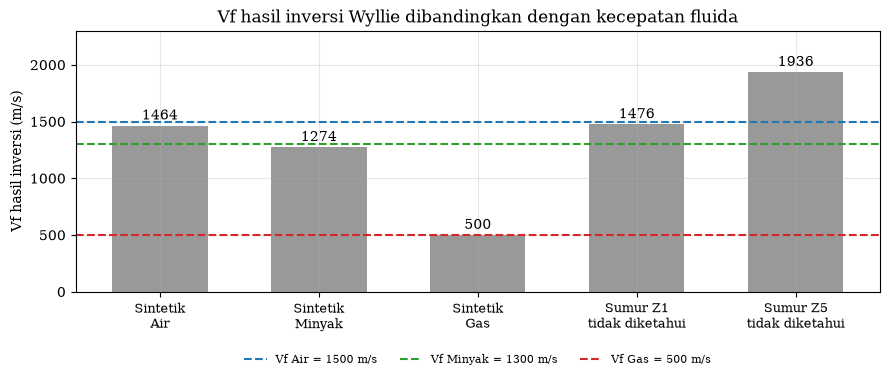

In [27]:
baris = []
for f, (Vf, rf, _) in FLUIDA.iterrows():
    d = wyllie(phi_sin, Vf, 5500) * (1 + NOISE*rng.standard_normal(N))
    M, rms, _ = inversi(model_W, phi_sin, d, m0=(4000, 2500), skala=(1000, 1000))
    tebak = (FLUIDA["Vf (m/s)"] - M[-1, 1]).abs().idxmin()
    baris.append(["Sintetik", f, M[-1, 0], M[-1, 1], tebak, rms[-1]])
for z in ["Z1", "Z5"]:
    s = sw[sw["Zona"] == z]
    M, rms, _ = inversi(model_W, s["phiD"].to_numpy(), s["Vp"].to_numpy(), m0=(4000, 2500), skala=(1000, 1000))
    tebak = (FLUIDA["Vf (m/s)"] - M[-1, 1]).abs().idxmin()
    baris.append([f"Sumur {z}", "tidak diketahui", M[-1, 0], M[-1, 1], tebak, rms[-1]])
fluida_inv = pd.DataFrame(baris, columns=["Data", "Fluida sebenarnya", "Vma (m/s)", "Vf (m/s)", "Vf terdekat", "RMS (m/s)"])
display(fluida_inv.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
for f, (Vf, rf, _) in FLUIDA.iterrows(): ax.axhline(Vf, color=WARNA[f], ls="--", label=f"Vf {f} = {Vf:.0f} m/s")
bar = ax.bar(fluida_inv["Data"] + "\n" + fluida_inv["Fluida sebenarnya"], fluida_inv["Vf (m/s)"], color="0.6", width=0.6)
ax.bar_label(bar, fmt="%.0f", padding=2)
ax.set(ylabel="Vf hasil inversi (m/s)", ylim=(0, 2300), title="Vf hasil inversi Wyllie dibandingkan dengan kecepatan fluida")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False); plt.xticks(fontsize=9)
plt.tight_layout(); simpan(fig, "17_identifikasi_fluida"); plt.show()

Pada data sintetik, $V_f$ hasil inversi selalu paling dekat dengan fluida yang sebenarnya. Pada data sumur, kolom "Vf terdekat" harus dibaca dengan hati-hati. $V_f$ Z5 lebih besar daripada kecepatan air, sehingga bukan kecepatan fluida yang sebenarnya, melainkan parameter semu yang ikut menyerap pengaruh rangka batuan yang lebih kompak pada kedalaman tersebut.

## Langkah 6 · Evaluasi Hasil Inversi

### 6.1 Residual

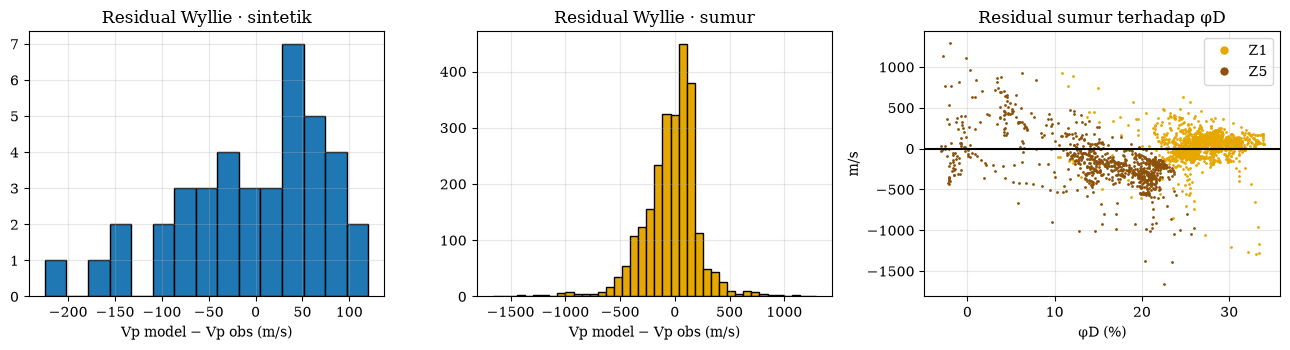

Residual sintetik : rata-rata -3.5 m/s, simpangan baku 81.5 m/s
Residual sumur    : rata-rata -31.7 m/s, simpangan baku 251.7 m/s


In [28]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
r_ws = model_W(phi_sin, M_ws[-1]) - Vp_sin_W
r_wd = model_W(x_wd, M_wd[-1]) - d_wd
axs[0].hist(r_ws, bins=15, color="C0", edgecolor="k"); axs[0].set(title="Residual Wyllie · sintetik", xlabel="Vp model − Vp obs (m/s)")
axs[1].hist(r_wd, bins=40, color="#e6a700", edgecolor="k"); axs[1].set(title="Residual Wyllie · sumur", xlabel="Vp model − Vp obs (m/s)")
for z, c in [("Z1", "#e6a700"), ("Z5", "#8c510a")]:
    m = (sw["Zona"] == z).to_numpy(); axs[2].plot(x_wd[m]*100, r_wd[m], ".", ms=2, color=c, label=z)
axs[2].axhline(0, color="k"); axs[2].set(title="Residual sumur terhadap φD", xlabel="φD (%)", ylabel="m/s"); axs[2].legend(markerscale=5)
plt.tight_layout(); simpan(fig, "18_residual"); plt.show()
print(f"Residual sintetik : rata-rata {r_ws.mean():+.1f} m/s, simpangan baku {r_ws.std():.1f} m/s")
print(f"Residual sumur    : rata-rata {r_wd.mean():+.1f} m/s, simpangan baku {r_wd.std():.1f} m/s")

### 6.2 Ketidakpastian dan korelasi parameter

Kovariansi parameter didekati dengan $\mathbf{C}_m=s^2(\mathbf{J}^T\mathbf{J})^{-1}$, dengan $\mathbf{J}$ matriks Jacobian residual terhadap parameter dan $s^2$ variansi residual (Aster dkk., 2018). Koefisien korelasi yang mendekati ±1 menandakan *trade-off*: kedua parameter dapat saling mengompensasi dan tetap menghasilkan misfit yang hampir sama.

In [29]:
def ketidakpastian(model, x, d_obs, m):
    m = np.asarray(m, float); r0 = model(x, m) - d_obs
    J = np.zeros((len(x), 2))
    for j in range(2):
        h = 1e-6 * max(abs(m[j]), 1e-6); mp, mm = m.copy(), m.copy(); mp[j] += h; mm[j] -= h
        J[:, j] = (model(x, mp) - model(x, mm)) / (2*h)
    s2 = np.sum(r0**2) / (len(x) - 2)
    C = s2 * np.linalg.inv(J.T @ J); sd = np.sqrt(np.diag(C))
    return sd, C[0, 1] / (sd[0]*sd[1])

baris = []
for nama, mod, x, d, M, lab in [("Wyllie · sintetik", model_W, phi_sin, Vp_sin_W, M_ws, ("Vma", "Vf")),
                                ("Gardner · sintetik", model_G, Vp_sin_G, rho_sin, M_gs, ("a", "b")),
                                ("Wyllie · sumur batupasir", model_W, x_wd, d_wd, M_wd, ("Vma", "Vf")),
                                ("Gardner · sumur seluruh litologi", model_G, x_gd, d_gd, M_gd, ("a", "b"))]:
    sd, rho12 = ketidakpastian(mod, x, d, M[-1])
    baris.append([nama, f"{lab[0]} = {M[-1,0]:.4g} ± {sd[0]:.2g}", f"{lab[1]} = {M[-1,1]:.4g} ± {sd[1]:.2g}", rho12])
display(pd.DataFrame(baris, columns=["Kasus", "Parameter 1 (± 1σ)", "Parameter 2 (± 1σ)", "Korelasi"]).round(3))

,Kasus,Parameter 1 (± 1σ),Parameter 2 (± 1σ),Korelasi
0,Wyllie · sintetik,Vma = 5627 ± 63,Vf = 1471 ± 21,-0.837
1,Gardner · sintetik,a = 0.3093 ± 0.033,b = 0.2499 ± 0.013,-1.000
2,Wyllie · sumur batupasir,Vma = 5479 ± 20,Vf = 1516 ± 6.7,-0.749
3,Gardner · sumur seluruh litologi,a = 0.328 ± 0.0035,b = 0.2435 ± 0.0013,-1.000


### 6.3 Uji tebakan awal

Inversi diulang dari lima tebakan awal yang berbeda. Bila semua lintasan menuju titik yang sama, solusi tidak bergantung pada tebakan awal.

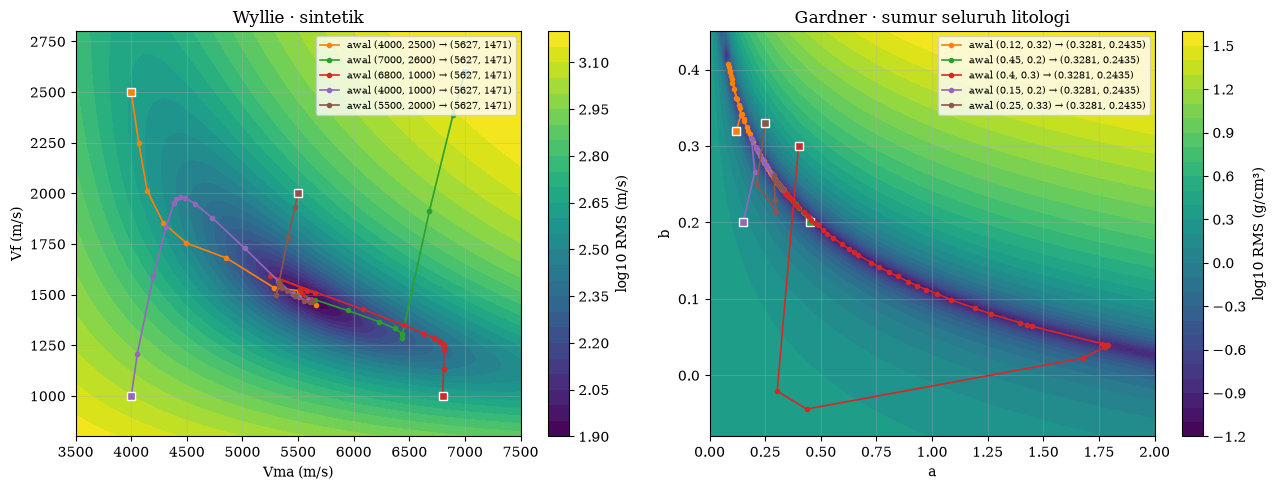

In [30]:
awal_W = [(4000, 2500), (7000, 2600), (6800, 1000), (4000, 1000), (5500, 2000)]
awal_G = [(0.12, 0.32), (0.45, 0.20), (0.40, 0.30), (0.15, 0.20), (0.25, 0.33)]
peta_W_lebar = peta_misfit(model_W, phi_sin, Vp_sin_W, np.linspace(3500, 7500, 80), np.linspace(800, 2800, 80))
peta_G_lebar = peta_misfit(model_G, x_gd, d_gd, np.linspace(0.0, 2.0, 80), np.linspace(-0.08, 0.45, 80))
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (mod, x, d, peta, awal, sk, lab, judul) in zip(axs, [
        (model_W, phi_sin, Vp_sin_W, peta_W_lebar, awal_W, (1000, 1000), ("Vma (m/s)", "Vf (m/s)"), "Wyllie · sintetik"),
        (model_G, x_gd, d_gd, peta_G_lebar, awal_G, (1, 1), ("a", "b"), "Gardner · sumur seluruh litologi")]):
    sat = "m/s" if lab[0].startswith("V") else "g/cm³"
    A, B, Z = peta
    cs = ax.contourf(A, B, np.log10(np.minimum(Z, np.nanpercentile(Z, 95))), levels=30, cmap="viridis")
    for i, m0 in enumerate(awal):
        M, rms, _ = inversi(mod, x, d, m0=m0, skala=sk)
        ax.plot(M[:, 0], M[:, 1], ".-", color=f"C{i+1}", lw=1.2, label=f"awal {m0} → ({M[-1,0]:.4g}, {M[-1,1]:.4g})")
        ax.plot(*m0, "s", color=f"C{i+1}", mec="w")
    ax.set(xlabel=lab[0], ylabel=lab[1], title=judul, xlim=(A.min(), A.max()), ylim=(B.min(), B.max()))
    ax.legend(fontsize=7, loc="upper right")
    fig.colorbar(cs, ax=ax, label=f"log10 RMS ({sat})")
plt.tight_layout(); simpan(fig, "19_uji_tebakan_awal"); plt.show()

### 6.4 Uji tingkat *noise*

Untuk setiap tingkat *noise* (0%, 2%, 5%, dan 10%), data sintetik Wyllie dibuat ulang sebanyak 30 kali dengan *noise* acak yang berbeda, lalu diinversi. Sebaran hasilnya menunjukkan seberapa stabil inversi terhadap kualitas data.

,Noise (%),Vma rata-rata,Vma sd,Vf rata-rata,Vf sd
0,0.0,5500.0,0.0,1500.0,0.0
1,2.0,5484.7,62.1,1498.3,15.8
2,5.0,5510.1,166.4,1487.6,52.0
3,10.0,5462.2,347.7,1468.8,88.4


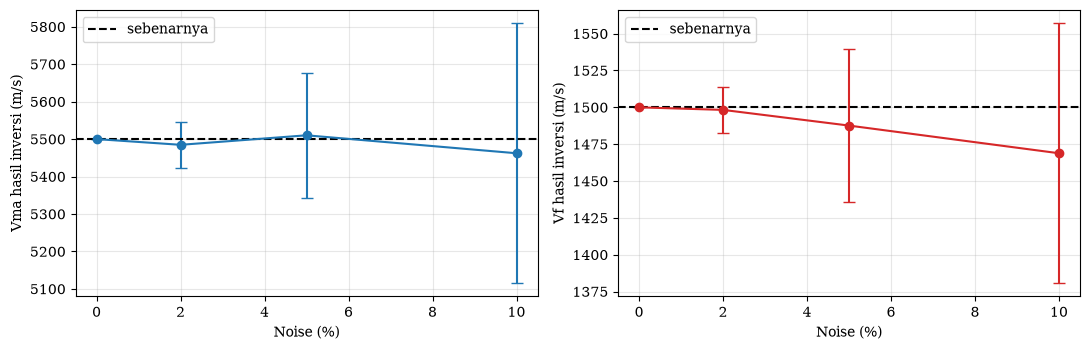

In [31]:
tingkat = [0.0, 0.02, 0.05, 0.10]
hasil_noise = []
for nz in tingkat:
    est = []
    for _ in range(30):
        d = wyllie(phi_sin, 1500, 5500) * (1 + nz*rng.standard_normal(N))
        M, _, _ = inversi(model_W, phi_sin, d, m0=(4000, 2500), skala=(1000, 1000))
        est.append(M[-1])
    est = np.array(est)
    hasil_noise.append([nz*100, est[:, 0].mean(), est[:, 0].std(), est[:, 1].mean(), est[:, 1].std()])
hn = pd.DataFrame(hasil_noise, columns=["Noise (%)", "Vma rata-rata", "Vma sd", "Vf rata-rata", "Vf sd"])
display(hn.round(1))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].errorbar(hn["Noise (%)"], hn["Vma rata-rata"], yerr=hn["Vma sd"], fmt="o-", capsize=4); axs[0].axhline(5500, color="k", ls="--", label="sebenarnya")
axs[1].errorbar(hn["Noise (%)"], hn["Vf rata-rata"], yerr=hn["Vf sd"], fmt="o-", capsize=4, color="C3"); axs[1].axhline(1500, color="k", ls="--", label="sebenarnya")
axs[0].set(xlabel="Noise (%)", ylabel="Vma hasil inversi (m/s)"); axs[1].set(xlabel="Noise (%)", ylabel="Vf hasil inversi (m/s)")
for ax in axs: ax.legend()
plt.tight_layout(); simpan(fig, "20_uji_noise"); plt.show()

## Langkah 7 · Pengembangan: Saturasi Fluida dan Model Gassmann

Pada Langkah 1–6, pori dianggap jenuh 100% oleh satu fluida. Di reservoir, pori sering terisi campuran air dan gas. Sifat campuran fluida dihitung dengan rata-rata Wood (Reuss) untuk modulus dan rata-rata volumetrik untuk densitas (Mavko dkk., 2009):

$$\frac{1}{K_f}=\frac{S_w}{K_w}+\frac{1-S_w}{K_g},\qquad \rho_f=S_w\rho_w+(1-S_w)\rho_g,\qquad V_f=\sqrt{K_f/\rho_f}\qquad(10)$$

Sebagai pembanding fisis, dipakai juga persamaan Gassmann (Gassmann, 1951), yang memisahkan kekakuan rangka kering dan modulus fluida:

$$K_{sat}=K_{dry}+\frac{\left(1-K_{dry}/K_{ma}\right)^2}{\phi/K_f+(1-\phi)/K_{ma}-K_{dry}/K_{ma}^2},\qquad \mu_{sat}=\mu_{dry},\qquad V_p=\sqrt{\frac{K_{sat}+\tfrac{4}{3}\mu_{sat}}{\rho_b}}\qquad(11)$$

Modulus rangka kering didekati dengan relasi Krief, $K_{dry}=K_{ma}(1-\phi)^{3/(1-\phi)}$ dan $\mu_{dry}=\mu_{ma}(1-\phi)^{3/(1-\phi)}$ (Krief dkk., 1990), dengan modulus kuarsa $K_{ma}$ = 36,6 GPa dan $\mu_{ma}$ = 45 GPa (Mavko dkk., 2009). Model Gassmann ditambahkan hanya sebagai pembanding untuk memperlihatkan keterbatasan model Wyllie pada gas.

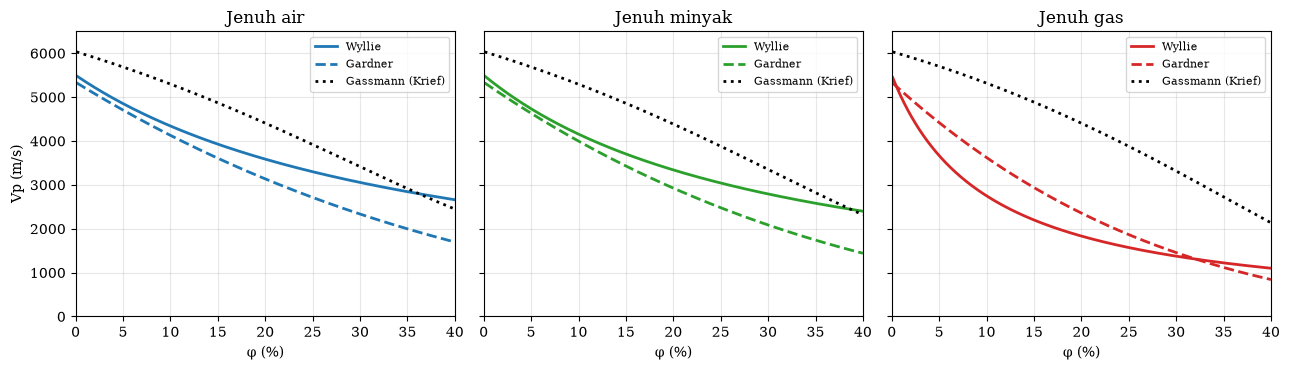

In [32]:
K_ma, mu_ma = 36.6e9, 45.0e9                     # modulus kuarsa (Pa)
def K_dari(Vf, rf): return rf*1000 * Vf**2       # K = rho V^2 (Pa)
K_w, K_o, K_g = [K_dari(*FLUIDA.loc[f, ["Vf (m/s)", "rho_f (g/cm3)"]]) for f in ["Air", "Minyak", "Gas"]]

def campur_fluida(Sw, K1=K_w, r1=1.00, K2=K_g, r2=0.20):
    # Persamaan (10): campuran air (fraksi Sw) dan fluida kedua
    Kf = 1.0 / (Sw/K1 + (1-Sw)/K2); rf = Sw*r1 + (1-Sw)*r2
    return Kf, rf, np.sqrt(Kf / (rf*1000))

def gassmann(phi, Kf, rf):
    # Persamaan (11) dengan rangka kering Krief
    fk = (1 - phi) ** (3 / (1 - phi))
    Kd, md_ = K_ma*fk, mu_ma*fk
    Ks = Kd + (1 - Kd/K_ma)**2 / (phi/Kf + (1-phi)/K_ma - Kd/K_ma**2)
    rb = rho_bulk(phi, rf) * 1000
    return np.sqrt((Ks + 4/3*md_) / rb)

# Kurva Vp-phi ketiga model untuk ketiga fluida
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
pg = np.linspace(0.001, 0.40, 300)
for ax, (f, (Vf, rf, _)) in zip(axs, FLUIDA.iterrows()):
    Kf = K_dari(Vf, rf)
    ax.plot(pg*100, wyllie(pg, Vf), color=WARNA[f], lw=2, label="Wyllie")
    ax.plot(pg*100, gardner(pg, rf), color=WARNA[f], lw=2, ls="--", label="Gardner")
    ax.plot(pg*100, gassmann(pg, Kf, rf), color="k", lw=2, ls=":", label="Gassmann (Krief)")
    ax.set(title=f"Jenuh {f.lower()}", xlabel="φ (%)", xlim=(0, 40), ylim=(0, 6500)); ax.legend(fontsize=8)
axs[0].set_ylabel("Vp (m/s)")
plt.tight_layout(); simpan(fig, "21_wyllie_gardner_gassmann"); plt.show()

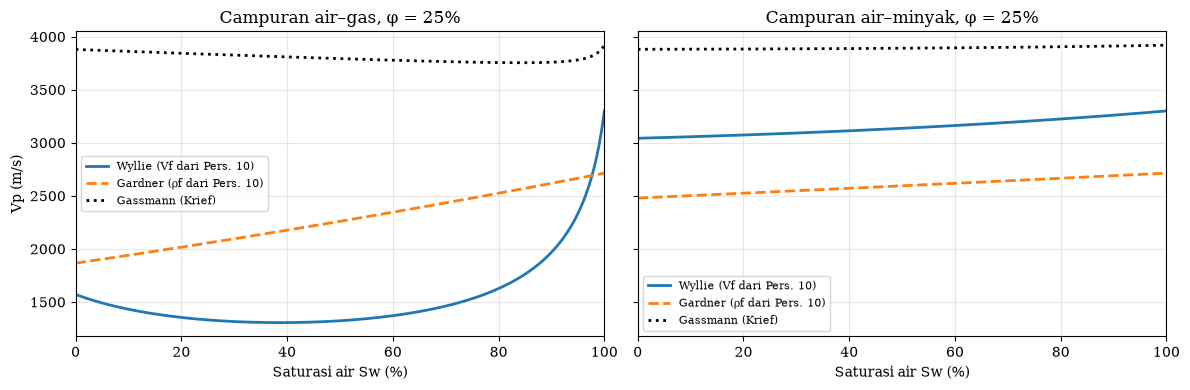

,Sw (%),Wyllie (m/s),Gardner (m/s),Gassmann (m/s)
0,0,1571.4,1866.1,3879.0
1,10,1432.0,1940.5,3860.8
2,50,1323.6,2260.4,3792.7
3,90,1969.1,2618.2,3758.7
4,100,3300.0,2714.0,3919.0


In [33]:
# Vp terhadap saturasi air pada phi = 25 % (campuran air-gas dan air-minyak)
phi_r = 0.25
Sw = np.linspace(0, 1, 201)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (nama, K2, r2) in zip(axs, [("gas", K_g, 0.20), ("minyak", K_o, 0.80)]):
    Kf, rf, Vf = campur_fluida(Sw, K2=K2, r2=r2)
    ax.plot(Sw*100, wyllie(phi_r, Vf), "C0", lw=2, label="Wyllie (Vf dari Pers. 10)")
    ax.plot(Sw*100, gardner(phi_r, rf), "C1", lw=2, ls="--", label="Gardner (ρf dari Pers. 10)")
    ax.plot(Sw*100, gassmann(phi_r, Kf, rf), "k", lw=2, ls=":", label="Gassmann (Krief)")
    ax.set(xlabel="Saturasi air Sw (%)", title=f"Campuran air–{nama}, φ = 25%", xlim=(0, 100)); ax.legend(fontsize=8)
axs[0].set_ylabel("Vp (m/s)")
plt.tight_layout(); simpan(fig, "22_vp_saturasi"); plt.show()

tab_sw = pd.DataFrame({"Sw (%)": [0, 10, 50, 90, 100]})
for kol, fn in [("Wyllie", lambda K, r, V: wyllie(phi_r, V)), ("Gardner", lambda K, r, V: gardner(phi_r, r)),
                ("Gassmann", lambda K, r, V: gassmann(phi_r, K, r))]:
    tab_sw[kol + " (m/s)"] = [fn(*campur_fluida(s/100)) for s in tab_sw["Sw (%)"]]
display(tab_sw.round(1))

## Langkah 8 · Seismogram Sintetik

Kecepatan dan densitas dari setiap model diubah menjadi respons seismik. Model tiga lapis terdiri atas serpih, batupasir ($\phi$ = 25%, setebal 40 ms TWT), dan serpih. Sifat serpih ($V_p$ = 3000 m/s, $\rho$ = 2,40 g/cm³) adalah **asumsi** untuk keperluan ilustrasi, bukan hasil pengukuran. Impedansi akustik, koefisien refleksi pada sudut datang normal, dan wavelet Ricker didefinisikan sebagai

$$Z=\rho V_p,\qquad R=\frac{Z_2-Z_1}{Z_2+Z_1},\qquad w(t)=\left(1-2\pi^2f^2t^2\right)e^{-\pi^2f^2t^2}\qquad(12)$$

Seismogram sintetik adalah konvolusi deret koefisien refleksi dengan wavelet, $s(t)=R(t)*w(t)$, dengan frekuensi dominan $f$ = 30 Hz.

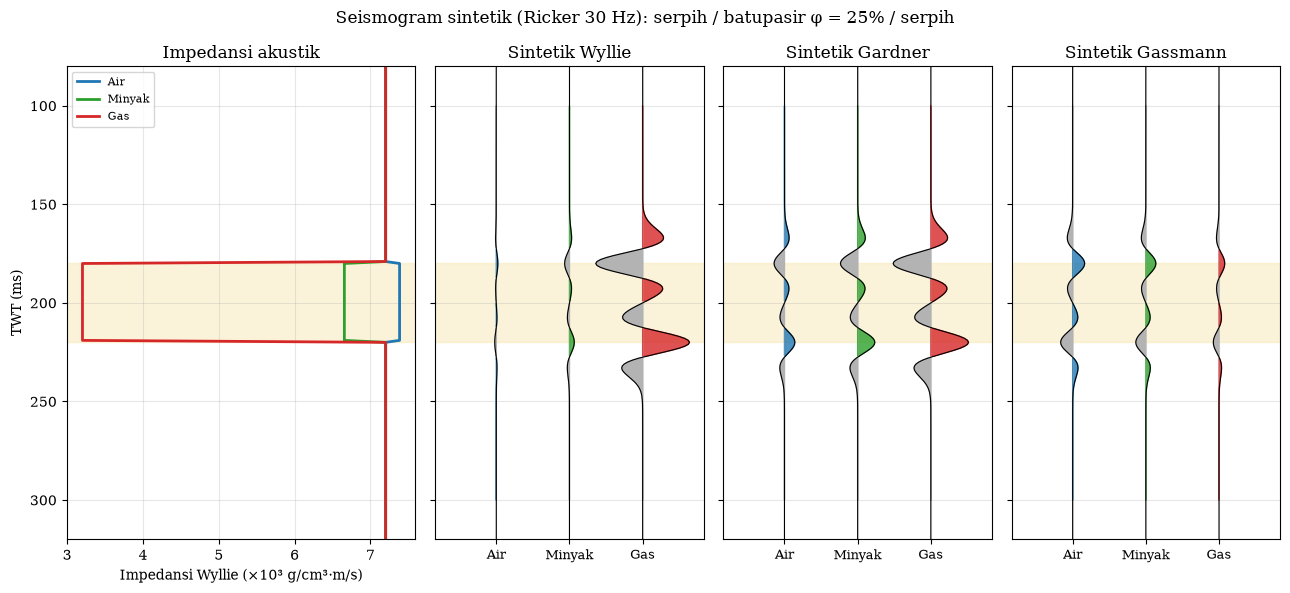

,Model,Fluida,Vp batupasir (m/s),ρb (g/cm³),R puncak batupasir,R dasar batupasir
0,Wyllie,Air,3300.000,2.238,0.013,-0.013
1,Wyllie,Minyak,3042.553,2.188,-0.039,0.039
2,Wyllie,Gas,1571.429,2.037,-0.384,0.384
3,Gardner,Air,2713.972,2.238,-0.085,0.085
4,Gardner,Minyak,2479.394,2.188,-0.141,0.141
5,Gardner,Gas,1866.138,2.037,-0.309,0.309
6,Gassmann,Air,3919.032,2.238,0.098,-0.098
7,Gassmann,Minyak,3880.492,2.188,0.082,-0.082
8,Gassmann,Gas,3879.035,2.037,0.047,-0.047


In [34]:
dt, f_dom = 0.001, 30.0
t = np.arange(0, 0.4, dt)
Vsh, rsh = 3000.0, 2.40                          # serpih (asumsi ilustrasi)
atas, bawah = 0.18, 0.22                         # batas batupasir (s, TWT)
tw = np.arange(-0.08, 0.08 + dt, dt)
ricker = (1 - 2*(np.pi*f_dom*tw)**2) * np.exp(-(np.pi*f_dom*tw)**2)

def seismogram(Vs, rs):
    Z = np.where((t >= atas) & (t < bawah), rs*Vs, rsh*Vsh)
    R = np.zeros_like(t); R[1:] = (Z[1:] - Z[:-1]) / (Z[1:] + Z[:-1])
    return Z, R, np.convolve(R, ricker, mode="same")

kasus = []
for model, fn in [("Wyllie", lambda f, Vf, rf: wyllie(phi_r, Vf)), ("Gardner", lambda f, Vf, rf: gardner(phi_r, rf)),
                  ("Gassmann", lambda f, Vf, rf: gassmann(phi_r, K_dari(Vf, rf), rf))]:
    for f, (Vf, rf, _) in FLUIDA.iterrows():
        Vs, rs = fn(f, Vf, rf), rho_bulk(phi_r, rf)
        Z, R, s = seismogram(Vs, rs)
        kasus.append(dict(Model=model, Fluida=f, Vp=Vs, rho=rs, Z=Z, R=R, s=s,
                          R_atas=R[np.argmin(abs(t - atas))], R_bawah=R[np.argmin(abs(t - bawah))]))

fig, axs = plt.subplots(1, 4, figsize=(13, 6), sharey=True, gridspec_kw=dict(width_ratios=[1.3, 1, 1, 1]))
for f in FLUIDA.index:
    k = [c for c in kasus if c["Model"] == "Wyllie" and c["Fluida"] == f][0]
    axs[0].plot(k["Z"]/1e3, t*1000, color=WARNA[f], lw=2, label=f)
axs[0].set(xlabel="Impedansi Wyllie (×10³ g/cm³·m/s)", ylabel="TWT (ms)", title="Impedansi akustik"); axs[0].legend(fontsize=8)
for ax, model in zip(axs[1:], ["Wyllie", "Gardner", "Gassmann"]):
    for i, f in enumerate(FLUIDA.index):
        k = [c for c in kasus if c["Model"] == model and c["Fluida"] == f][0]
        x0 = i * 0.6; tr = k["s"] / 0.5 * 0.5
        ax.plot(x0 + tr, t*1000, "k", lw=0.8)
        ax.fill_betweenx(t*1000, x0, x0 + tr, where=tr > 0, color=WARNA[f], alpha=0.8)
        ax.fill_betweenx(t*1000, x0, x0 + tr, where=tr < 0, color="0.7")
    ax.set(title=f"Sintetik {model}", xticks=[0, 0.6, 1.2], xlim=(-0.5, 1.7))
    ax.set_xticklabels(FLUIDA.index, fontsize=9)
for ax in axs:
    ax.axhspan(atas*1000, bawah*1000, color="#f6e3a1", alpha=0.4, zorder=0)
axs[0].set_ylim(320, 80)
fig.suptitle("Seismogram sintetik (Ricker 30 Hz): serpih / batupasir φ = 25% / serpih")
plt.tight_layout(); simpan(fig, "23_seismogram_sintetik"); plt.show()

tab_R = pd.DataFrame([{k: c[k] for k in ["Model", "Fluida", "Vp", "rho", "R_atas", "R_bawah"]} for c in kasus])
tab_R.columns = ["Model", "Fluida", "Vp batupasir (m/s)", "ρb (g/cm³)", "R puncak batupasir", "R dasar batupasir"]
display(tab_R.round(3))

Pada model Wyllie, batupasir jenuh gas menghasilkan koefisien refleksi negatif yang kuat di puncak batupasir (−0,38), jauh lebih besar daripada air (+0,01) dan minyak (−0,04). Pola ini dikenal sebagai efek *bright spot*. Model Gardner juga memberi refleksi negatif untuk gas (−0,31), tetapi air dan minyak sudah ikut negatif karena Vp batupasir Gardner lebih rendah. Pada model Gassmann dengan rangka Krief, Vp batupasir hampir tidak berubah terhadap jenis fluida (3879–3919 m/s), sehingga koefisien refleksi gas hanya turun dari +0,10 menjadi +0,05, terutama karena densitasnya lebih rendah. Jadi, pemilihan model fisika batuan secara langsung mengubah amplitudo seismik yang diprediksi, dan model Wyllie cenderung melebih-lebihkan efek gas.

## Langkah 9 · Kesimpulan

1. **Model = rumus.** Model Wyllie (Persamaan 2) dan relasi Gardner dengan pencampuran densitas (Persamaan 5) berhasil diterjemahkan menjadi fungsi Python. Hasil *forward modeling* sama dengan Tabel 2 pada laporan, misalnya contoh papan $\phi=0{,}10$ jenuh air menghasilkan $V_p$ = 4342,1 m/s (Wyllie) dan 4129,1 m/s (Gardner). Pada model Wyllie, *slowness* berubah linear terhadap porositas.

2. **Inversi porositas.** Metode Newton menemukan porositas dari $V_p$ = 3000 m/s dalam 5 iterasi untuk Wyllie ($\phi$ = 31,25%) dan 4 iterasi untuk Gardner ($\phi$ = 21,56%), sama persis dengan solusi analitik. Untuk kecepatan yang sama, kedua model memberikan porositas yang berbeda hampir 10%, sehingga pilihan model sangat menentukan hasil interpretasi. Pada data sumur, porositas sonik hasil inversi Wyllie sesuai dengan porositas densitas (bias −0,42%, RMS 3,73%), sedangkan inversi Gardner dengan $a=0{,}31$ dan $b=0{,}25$ cenderung terlalu kecil (bias −6,64%).

3. **Inversi parameter pada data sintetik.** BFGS menemukan kembali parameter sebenarnya dari tebakan awal yang jauh: $V_{ma}$ = 5627 ± 63 m/s dan $V_f$ = 1471 ± 21 m/s dalam 14 iterasi (sebenarnya 5500 dan 1500 m/s), serta $a$ = 0,309 ± 0,033 dan $b$ = 0,250 ± 0,013 dalam 27 iterasi (sebenarnya 0,31 dan 0,25). Uji 30 realisasi *noise* menunjukkan rata-rata hasil inversi tetap dekat dengan nilai sebenarnya, tetapi sebarannya membesar seiring *noise*; simpangan baku $V_f$ naik dari 16 m/s (*noise* 2%) menjadi 88 m/s (*noise* 10%).

4. **Inversi parameter pada data sumur.** Inversi Wyllie pada 2.521 sampel batupasir menghasilkan $V_{ma}$ = 5479 ± 20 m/s dan $V_f$ = 1516 ± 7 m/s. Nilai ini sangat dekat dengan parameter yang dipakai pada laporan (5500 dan 1500 m/s), sehingga data sumur mendukung pemilihan parameter tersebut. Inversi Gardner pada seluruh litologi menghasilkan $a$ = 0,328 dan $b$ = 0,2435, dekat dengan nilai Gardner dkk. (1974), sedangkan inversi pada batupasir saja menghasilkan $a$ = 0,187 dan $b$ = 0,306.

5. **Trade-off dan non-uniqueness.** Korelasi antara $a$ dan $b$ mendekati −1 dan peta misfitnya membentuk lembah panjang yang melengkung. Artinya, banyak pasangan $(a,b)$ menghasilkan kurva yang hampir sama pada rentang data, sehingga kedua konstanta tidak boleh ditafsirkan secara terpisah. Pada Wyllie, korelasi $V_{ma}$–$V_f$ juga negatif (−0,84 pada data sintetik), tetapi semua tebakan awal tetap konvergen ke solusi yang sama.

6. **Identifikasi fluida.** Pada data sintetik, $V_f$ hasil inversi selalu paling dekat dengan fluida yang sebenarnya (air, minyak, dan gas). Pada data sumur, Z1 menghasilkan $V_f$ = 1476 m/s yang mendekati air, tetapi Z5 menghasilkan $V_f$ = 1936 m/s, lebih besar daripada kecepatan air. Nilai ini tidak dapat ditafsirkan sebagai kecepatan fluida yang sebenarnya. $V_f$ pada model Wyllie berperan sebagai parameter semu yang ikut menyerap pengaruh kekakuan rangka, kompaksi, dan sementasi batuan, serta asumsi $\rho_f$ = 1,00 g/cm³ pada perhitungan $\phi_D$.

7. **Saturasi fluida.** Pada $\phi$ = 25%, sedikit gas saja (Sw = 90%) sudah menurunkan $V_p$ model Wyllie dari 3300 menjadi 1969 m/s, karena modulus campuran air–gas (Persamaan 10) didominasi oleh gas. Model Gardner turun lebih landai (2714 menjadi 2618 m/s), sedangkan model Gassmann dengan rangka Krief hanya berubah sekitar 4% di seluruh rentang saturasi.

8. **Seismogram sintetik.** Koefisien refleksi di puncak batupasir jenuh gas adalah −0,38 (Wyllie), −0,31 (Gardner), dan +0,05 (Gassmann). Artinya, model yang dipilih menentukan apakah zona gas tampak sebagai *bright spot* atau tidak, sehingga interpretasi amplitudo seismik harus selalu menyebutkan model fisika batuan yang dipakai.

## Daftar Pustaka

Aster, R. C., Borchers, B., & Thurber, C. H. (2018). *Parameter estimation and inverse problems* (3rd ed.). Elsevier.

Batzle, M., & Wang, Z. (1992). Seismic properties of pore fluids. *Geophysics, 57*(11), 1396–1408. https://doi.org/10.1190/1.1443207

Equinor. (2018). *Volve field data set* [Data set]. https://www.equinor.com/energy/volve-data-sharing

Gassmann, F. (1951). Über die Elastizität poröser Medien. *Vierteljahrsschrift der Naturforschenden Gesellschaft in Zürich, 96*, 1–23.

Gardner, G. H. F., Gardner, L. W., & Gregory, A. R. (1974). Formation velocity and density—The diagnostic basics for stratigraphic traps. *Geophysics, 39*(6), 770–780. https://doi.org/10.1190/1.1440465

Krief, M., Garat, J., Stellingwerff, J., & Ventre, J. (1990). A petrophysical interpretation using the velocities of P and S waves (full-waveform sonic). *The Log Analyst, 31*(6), 355–369.

Mavko, G., Mukerji, T., & Dvorkin, J. (2009). *The rock physics handbook: Tools for seismic analysis of porous media* (2nd ed.). Cambridge University Press. https://doi.org/10.1017/CBO9780511626753

Wyllie, M. R. J., Gregory, A. R., & Gardner, L. W. (1956). Elastic wave velocities in heterogeneous and porous media. *Geophysics, 21*(1), 41–70. https://doi.org/10.1190/1.1438217